In [2]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit,
    StratifiedGroupKFold
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")


All libraries imported successfully!


## 3. Exploratory Data Analysis (EDA)

### 3.1 Dataset Structure
### 3.2 Annotation Analysis
### 3.3 Class Distribution
### 3.4 Sample Image Visualization

In [3]:
for root, dirs, files in os.walk(DATASET_ROOT):

    depth = len(
        Path(root).relative_to(DATASET_ROOT).parts
    )

    if depth >= 3:
        dirs.clear()

    indent = "    " * depth

    print(f"{indent}{Path(root).name}/")

    for file in sorted(files)[:3]:
        print(f"{indent}    {file}")

    if len(files) > 3:
        print(f"{indent}    ...")


NameError: name 'DATASET_ROOT' is not defined

In [4]:

import os
from pathlib import Path

# Define dataset path
DATASET_ROOT = Path("/kaggle/input")

# Explore dataset structure
for root, dirs, files in os.walk(DATASET_ROOT):

    depth = len(
        Path(root).relative_to(DATASET_ROOT).parts
    )

    if depth >= 3:
        dirs.clear()

    indent = "    " * depth

    print(f"{indent}{Path(root).name}/")

    for file in sorted(files)[:3]:
        print(f"{indent}    {file}")

    if len(files) > 3:
        print(f"{indent}    ...")


input/


In [6]:

from pathlib import Path

DATASET_ROOT = Path("/kaggle/input")

datasets = list(DATASET_ROOT.iterdir())

if datasets:
    print("Dataset successfully added!")

    for folder in datasets:
        print(folder)
else:
    print("No dataset found!")


Dataset successfully added!
/kaggle/input/datasets


In [7]:

from pathlib import Path

DATASET_ROOT = Path("/kaggle/input/datasets")

# Find all CSV annotation files
csv_files = sorted(DATASET_ROOT.rglob("*.csv"))

print("Total CSV Files:", len(csv_files))
print("=" * 70)

for i, file in enumerate(csv_files[:30], 1):
    print(f"{i}. {file}")

print("=" * 70)


Total CSV Files: 48
1. /kaggle/input/datasets/mbornoe/lisa-traffic-light-dataset/Annotations/Annotations/daySequence1/frameAnnotationsBOX.csv
2. /kaggle/input/datasets/mbornoe/lisa-traffic-light-dataset/Annotations/Annotations/daySequence1/frameAnnotationsBULB.csv
3. /kaggle/input/datasets/mbornoe/lisa-traffic-light-dataset/Annotations/Annotations/daySequence2/frameAnnotationsBOX.csv
4. /kaggle/input/datasets/mbornoe/lisa-traffic-light-dataset/Annotations/Annotations/daySequence2/frameAnnotationsBULB.csv
5. /kaggle/input/datasets/mbornoe/lisa-traffic-light-dataset/Annotations/Annotations/dayTrain/dayClip1/frameAnnotationsBOX.csv
6. /kaggle/input/datasets/mbornoe/lisa-traffic-light-dataset/Annotations/Annotations/dayTrain/dayClip1/frameAnnotationsBULB.csv
7. /kaggle/input/datasets/mbornoe/lisa-traffic-light-dataset/Annotations/Annotations/dayTrain/dayClip10/frameAnnotationsBOX.csv
8. /kaggle/input/datasets/mbornoe/lisa-traffic-light-dataset/Annotations/Annotations/dayTrain/dayClip10/fra

In [8]:


if csv_files:

    annotation_path = csv_files[0]

    df = pd.read_csv(
        annotation_path,
        sep=None,
        engine="python"
    )

    print("Annotation File:")
    print(annotation_path)

    print("\nDataset Shape:", df.shape)

    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nFirst 5 Rows:")
    display(df.head())

    print("\nMissing Values:")
    print(df.isnull().sum())

else:
    print("No CSV annotation files found.")


Annotation File:
/kaggle/input/datasets/mbornoe/lisa-traffic-light-dataset/Annotations/Annotations/daySequence1/frameAnnotationsBOX.csv

Dataset Shape: (7900, 10)

Column Names:
['Filename', 'Annotation tag', 'Upper left corner X', 'Upper left corner Y', 'Lower right corner X', 'Lower right corner Y', 'Origin file', 'Origin frame number', 'Origin track', 'Origin track frame number']

First 5 Rows:


,Filename,Annotation tag,Upper left corner X,Upper left corner Y,Lower right corner X,Lower right corner Y,Origin file,Origin frame number,Origin track,Origin track frame number
0,dayTest/daySequence1--00000.jpg,stop,706,478,718,500,dayTest/daySequence1/Day1EveningShutter0.00020...,0,dayTest/daySequence1/Day1EveningShutter0.00020...,0
1,dayTest/daySequence1--00001.jpg,stop,705,475,720,497,dayTest/daySequence1/Day1EveningShutter0.00020...,1,dayTest/daySequence1/Day1EveningShutter0.00020...,1
2,dayTest/daySequence1--00002.jpg,stop,707,476,719,494,dayTest/daySequence1/Day1EveningShutter0.00020...,2,dayTest/daySequence1/Day1EveningShutter0.00020...,2
3,dayTest/daySequence1--00005.jpg,stop,708,474,720,492,dayTest/daySequence1/Day1EveningShutter0.00020...,5,dayTest/daySequence1/Day1EveningShutter0.00020...,5
4,dayTest/daySequence1--00006.jpg,stop,707,470,722,492,dayTest/daySequence1/Day1EveningShutter0.00020...,6,dayTest/daySequence1/Day1EveningShutter0.00020...,6



Missing Values:
Filename                     0
Annotation tag               0
Upper left corner X          0
Upper left corner Y          0
Lower right corner X         0
Lower right corner Y         0
Origin file                  0
Origin frame number          0
Origin track                 0
Origin track frame number    0
dtype: int64


In [9]:


DATASET_ROOT = Path(
    "/kaggle/input/datasets/mbornoe/lisa-traffic-light-dataset"
)

# Find bounding box annotation files
box_files = sorted(
    DATASET_ROOT.rglob("frameAnnotationsBOX.csv")
)

print("Total Bounding Box CSV Files:", len(box_files))

all_annotations = []

for file in box_files:

    temp_df = pd.read_csv(
        file,
        sep=None,
        engine="python"
    )

    # Preserve annotation source information
    temp_df["Sequence"] = file.parent.name
    temp_df["Annotation source"] = str(
        file.relative_to(DATASET_ROOT)
    )

    all_annotations.append(temp_df)

    print(file.parent.name, ":", len(temp_df))

# Combine all annotation data
annotations_df = pd.concat(
    all_annotations,
    ignore_index=True
)

print("\nCombined Dataset Shape:")
print(annotations_df.shape)

print("\nUnique Class Labels:")
print(annotations_df["Annotation tag"].unique())

print("\nClass Distribution:")
print(
    annotations_df["Annotation tag"].value_counts()
)

print("\nSequence Distribution:")
print(
    annotations_df["Sequence"].value_counts()
)


Total Bounding Box CSV Files: 24
daySequence1 : 7900
daySequence2 : 10120
dayClip1 : 7979
dayClip10 : 137
dayClip11 : 1260
dayClip12 : 229
dayClip13 : 1249
dayClip2 : 2173
dayClip3 : 1131
dayClip4 : 786
dayClip5 : 9705
dayClip6 : 1152
dayClip7 : 8076
dayClip8 : 1993
dayClip9 : 1940
nightSequence1 : 18514
nightSequence2 : 21115
nightClip1 : 1743
nightClip2 : 4499
nightClip3 : 2018
nightClip4 : 2520
nightClip5 : 3236
sample-dayClip6 : 1152
sample-nightClip1 : 1743

Combined Dataset Shape:
(112370, 12)

Unique Class Labels:
['stop' 'go' 'warning' 'warningLeft' 'stopLeft' 'goForward' 'goLeft']

Class Distribution:
Annotation tag
go             48892
stop           44730
stopLeft       13048
warning         2669
goLeft          2476
warningLeft      350
goForward        205
Name: count, dtype: int64

Sequence Distribution:
Sequence
nightSequence2       21115
nightSequence1       18514
daySequence2         10120
dayClip5              9705
dayClip7              8076
dayClip1              7979

In [10]:

# =============================================
# 9. DATA CLEANING AND CLASS FILTERING
# =============================================

# Preserve original annotation data
clean_df = annotations_df.copy()

print("Original Annotations:", len(clean_df))

# Remove sample sequences
clean_df = clean_df[
    ~clean_df["Sequence"].str.startswith("sample-")
].copy()

print("After Removing Sample Sequences:",
      len(clean_df))

# Remove duplicate bounding box annotations
duplicate_columns = [
    "Sequence",
    "Filename",
    "Annotation tag",
    "Upper left corner X",
    "Upper left corner Y",
    "Lower right corner X",
    "Lower right corner Y"
]

before = len(clean_df)

clean_df = clean_df.drop_duplicates(
    subset=duplicate_columns
).copy()

print("Duplicate Annotations Removed:",
      before - len(clean_df))

# Define target classes
target_classes = ["stop", "warning", "go"]

# Keep only target classes
filtered_df = clean_df[
    clean_df["Annotation tag"].isin(target_classes)
].copy()

# Convert original labels into class names
class_mapping = {
    "stop": "Red",
    "warning": "Yellow",
    "go": "Green"
}

filtered_df["Class"] = filtered_df[
    "Annotation tag"
].map(class_mapping)

# Assign numerical class IDs
label_mapping = {
    "Red": 0,
    "Yellow": 1,
    "Green": 2
}

filtered_df["Label"] = filtered_df[
    "Class"
].map(label_mapping)

# Reset index
filtered_df.reset_index(drop=True, inplace=True)

# Display final annotation information
print("\n" + "=" * 50)

print("Filtered Dataset Shape:",
      filtered_df.shape)

print("Total Target Annotations:",
      len(filtered_df))

print("Total Sequences:",
      filtered_df["Sequence"].nunique())

print("\nClass Distribution:")
print(filtered_df["Class"].value_counts())

print("\nClass IDs:")
print(label_mapping)

print("\nMissing Values:")
print(filtered_df.isnull().sum())

print("\nSample Data:")
display(filtered_df.head())

print("\nData Cleaning and Filtering Completed!")


Original Annotations: 112370
After Removing Sample Sequences: 109475
Duplicate Annotations Removed: 16

Filtered Dataset Shape: (93694, 14)
Total Target Annotations: 93694
Total Sequences: 22

Class Distribution:
Class
Green     46707
Red       44318
Yellow     2669
Name: count, dtype: int64

Class IDs:
{'Red': 0, 'Yellow': 1, 'Green': 2}

Missing Values:
Filename                     0
Annotation tag               0
Upper left corner X          0
Upper left corner Y          0
Lower right corner X         0
Lower right corner Y         0
Origin file                  0
Origin frame number          0
Origin track                 0
Origin track frame number    0
Sequence                     0
Annotation source            0
Class                        0
Label                        0
dtype: int64

Sample Data:


,Filename,Annotation tag,Upper left corner X,Upper left corner Y,Lower right corner X,Lower right corner Y,Origin file,Origin frame number,Origin track,Origin track frame number,Sequence,Annotation source,Class,Label
0,dayTest/daySequence1--00000.jpg,stop,706,478,718,500,dayTest/daySequence1/Day1EveningShutter0.00020...,0,dayTest/daySequence1/Day1EveningShutter0.00020...,0,daySequence1,Annotations/Annotations/daySequence1/frameAnno...,Red,0
1,dayTest/daySequence1--00001.jpg,stop,705,475,720,497,dayTest/daySequence1/Day1EveningShutter0.00020...,1,dayTest/daySequence1/Day1EveningShutter0.00020...,1,daySequence1,Annotations/Annotations/daySequence1/frameAnno...,Red,0
2,dayTest/daySequence1--00002.jpg,stop,707,476,719,494,dayTest/daySequence1/Day1EveningShutter0.00020...,2,dayTest/daySequence1/Day1EveningShutter0.00020...,2,daySequence1,Annotations/Annotations/daySequence1/frameAnno...,Red,0
3,dayTest/daySequence1--00005.jpg,stop,708,474,720,492,dayTest/daySequence1/Day1EveningShutter0.00020...,5,dayTest/daySequence1/Day1EveningShutter0.00020...,5,daySequence1,Annotations/Annotations/daySequence1/frameAnno...,Red,0
4,dayTest/daySequence1--00006.jpg,stop,707,470,722,492,dayTest/daySequence1/Day1EveningShutter0.00020...,6,dayTest/daySequence1/Day1EveningShutter0.00020...,6,daySequence1,Annotations/Annotations/daySequence1/frameAnno...,Red,0



Data Cleaning and Filtering Completed!


DATASET DISTRIBUTION TABLE


,Class,Class ID,Annotations,Percentage (%)
0,Red,0,44318,47.30
1,Yellow,1,2669,2.85
2,Green,2,46707,49.85


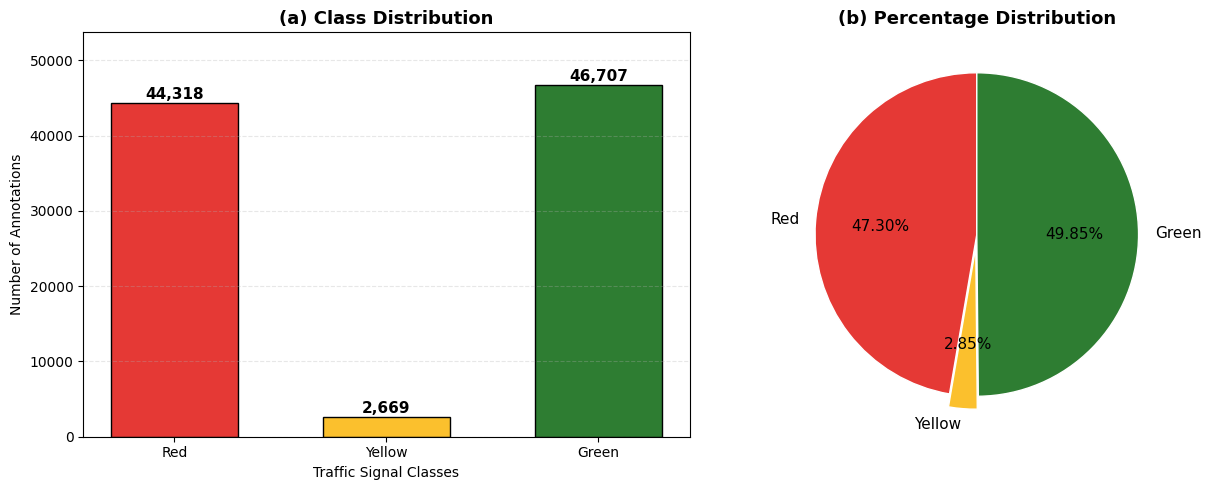


Files saved successfully!
class_distribution.pdf
class_distribution.png
dataset_distribution.csv


In [11]:

# =============================================
# 10. DATASET DISTRIBUTION AND VISUALIZATION
# =============================================

# Define class order and colors
class_order = ["Red", "Yellow", "Green"]

colors = ["#E53935", "#FBC02D", "#2E7D32"]

# Calculate class distribution
class_counts = filtered_df["Class"].value_counts()
class_counts = class_counts.reindex(
    class_order, fill_value=0
)

# Create dataset distribution table
distribution_table = pd.DataFrame({
    "Class": class_order,
    "Class ID": [0, 1, 2],
    "Annotations": class_counts.values,
    "Percentage (%)": (
        class_counts.values / len(filtered_df) * 100
    ).round(2)
})

print("DATASET DISTRIBUTION TABLE")
display(distribution_table)

# Create output directory
OUTPUT_DIR = Path("/kaggle/working/research_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save distribution table
distribution_table.to_csv(
    OUTPUT_DIR / "dataset_distribution.csv",
    index=False
)

# Create bar chart and pie chart
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Bar chart
bars = axes[0].bar(
    class_order,
    class_counts.values,
    color=colors,
    edgecolor="black",
    width=0.6
)

axes[0].set_title(
    "(a) Class Distribution",
    fontsize=13,
    fontweight="bold"
)

axes[0].set_xlabel("Traffic Signal Classes")
axes[0].set_ylabel("Number of Annotations")

axes[0].set_ylim(0, class_counts.max() * 1.15)

axes[0].grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

for bar, count in zip(bars, class_counts.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 500,
        f"{count:,}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

# Pie chart
axes[1].pie(
    class_counts.values,
    labels=class_order,
    colors=colors,
    autopct="%1.2f%%",
    startangle=90,
    explode=(0, 0.08, 0),
    wedgeprops={"edgecolor": "white"},
    textprops={"fontsize": 11}
)

axes[1].set_title(
    "(b) Percentage Distribution",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()

# Save publication-quality figures
plt.savefig(
    OUTPUT_DIR / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    OUTPUT_DIR / "class_distribution.pdf",
    bbox_inches="tight"
)

plt.show()

print("\nFiles saved successfully!")

for file in sorted(OUTPUT_DIR.iterdir()):
    print(file.name)


In [12]:

# =============================================
# 11. IMAGE PATH MAPPING AND VALIDATION
# =============================================

from collections import defaultdict

# Dataset location
DATASET_ROOT = Path(
    "/kaggle/input/datasets/mbornoe/lisa-traffic-light-dataset"
)

# Supported image formats
image_extensions = {".jpg", ".jpeg", ".png"}

# Create image filename index
image_index = defaultdict(list)

total_images = 0

print("Searching for image files...\n")

for root, dirs, files in os.walk(DATASET_ROOT):

    # Exclude sample directories
    dirs[:] = [
        d for d in dirs
        if not d.lower().startswith("sample")
    ]

    for file in files:

        if Path(file).suffix.lower() in image_extensions:

            image_path = Path(root) / file

            image_index[file].append(image_path)

            total_images += 1

print("Total Image Files Found:", total_images)
print("Unique Image Filenames:", len(image_index))

# Show sample image paths
print("\nSample Image Paths:")

for paths in list(image_index.values())[:5]:
    print(paths[0])

# Match annotations with image paths
def find_image_path(filename, sequence):

    basename = Path(filename).name

    candidates = image_index.get(basename, [])

    if not candidates:
        return None, "Missing"

    # Prioritize matching video sequence
    sequence_matches = [
        p for p in candidates
        if sequence.lower() in [
            part.lower() for part in p.parts
        ]
    ]

    if len(sequence_matches) == 1:
        return str(sequence_matches[0]), "Matched"

    if len(sequence_matches) > 1:
        return None, "Ambiguous"

    if len(candidates) == 1:
        return str(candidates[0]), "Matched by filename"

    return None, "Ambiguous"


# Preserve filtered annotation data
mapped_df = filtered_df.copy()

# Perform image path mapping
results = [
    find_image_path(filename, sequence)
    for filename, sequence in zip(
        mapped_df["Filename"],
        mapped_df["Sequence"]
    )
]

mapped_df["Image_Path"] = [r[0] for r in results]
mapped_df["Mapping_Status"] = [r[1] for r in results]

# Calculate mapping results
matched_count = mapped_df["Image_Path"].notna().sum()
unresolved_count = mapped_df["Image_Path"].isna().sum()

print("\n" + "=" * 60)

print("IMAGE PATH MAPPING RESULTS")

print("=" * 60)

print("Total Annotations:", len(mapped_df))
print("Matched Annotations:", matched_count)
print("Unresolved Annotations:", unresolved_count)

print(
    "Matching Rate:",
    round(matched_count / len(mapped_df) * 100, 2),
    "%"
)

print("\nMapping Status:")
print(mapped_df["Mapping_Status"].value_counts())

# Check mapping results by sequence
print("\nSequence-wise Mapping Results:")

display(pd.crosstab(
    mapped_df["Sequence"],
    mapped_df["Mapping_Status"]
))

# Display matched samples
print("\nSample Mapped Images:")

display(
    mapped_df.loc[
        mapped_df["Image_Path"].notna(),
        ["Filename", "Class", "Sequence", "Image_Path"]
    ].head()
)

# Display unresolved samples
if unresolved_count > 0:

    print("\nUnresolved Image Samples:")

    display(
        mapped_df.loc[
            mapped_df["Image_Path"].isna(),
            ["Filename", "Sequence", "Mapping_Status"]
        ].head(10)
    )

print("\nImage Path Mapping Completed!")


Searching for image files...

Total Image Files Found: 43016
Unique Image Filenames: 43016

Sample Image Paths:
/kaggle/input/datasets/mbornoe/lisa-traffic-light-dataset/daySequence1/daySequence1/frames/daySequence1--00000.jpg
/kaggle/input/datasets/mbornoe/lisa-traffic-light-dataset/daySequence1/daySequence1/frames/daySequence1--00001.jpg
/kaggle/input/datasets/mbornoe/lisa-traffic-light-dataset/daySequence1/daySequence1/frames/daySequence1--00002.jpg
/kaggle/input/datasets/mbornoe/lisa-traffic-light-dataset/daySequence1/daySequence1/frames/daySequence1--00003.jpg
/kaggle/input/datasets/mbornoe/lisa-traffic-light-dataset/daySequence1/daySequence1/frames/daySequence1--00004.jpg

IMAGE PATH MAPPING RESULTS
Total Annotations: 93694
Matched Annotations: 93694
Unresolved Annotations: 0
Matching Rate: 100.0 %

Mapping Status:
Mapping_Status
Matched    93694
Name: count, dtype: int64

Sequence-wise Mapping Results:


Mapping_Status,Matched
Sequence,
dayClip1,7979
dayClip10,109
dayClip11,1260
dayClip12,229
dayClip13,1249
dayClip2,1520
dayClip3,1131
dayClip4,786
dayClip5,6935



Sample Mapped Images:


,Filename,Class,Sequence,Image_Path
0,dayTest/daySequence1--00000.jpg,Red,daySequence1,/kaggle/input/datasets/mbornoe/lisa-traffic-li...
1,dayTest/daySequence1--00001.jpg,Red,daySequence1,/kaggle/input/datasets/mbornoe/lisa-traffic-li...
2,dayTest/daySequence1--00002.jpg,Red,daySequence1,/kaggle/input/datasets/mbornoe/lisa-traffic-li...
3,dayTest/daySequence1--00005.jpg,Red,daySequence1,/kaggle/input/datasets/mbornoe/lisa-traffic-li...
4,dayTest/daySequence1--00006.jpg,Red,daySequence1,/kaggle/input/datasets/mbornoe/lisa-traffic-li...



Image Path Mapping Completed!


In [ ]:

# =============================================
# 12. BOUNDING BOX VALIDATION
# =============================================

from tqdm.auto import tqdm

# Preserve mapped annotation data
validation_df = mapped_df.copy()
validation_df.reset_index(drop=True, inplace=True)

# Bounding box columns
coordinate_columns = [
    "Upper left corner X",
    "Upper left corner Y",
    "Lower right corner X",
    "Lower right corner Y"
]

# Initialize validation columns
validation_df["Image_Width"] = 0
validation_df["Image_Height"] = 0
validation_df["BBox_Width"] = 0
validation_df["BBox_Height"] = 0
validation_df["Validation_Status"] = "Unchecked"

# Count referenced unique images
unique_images = validation_df["Image_Path"].nunique()

print("Total Annotations:", len(validation_df))
print("Unique Referenced Images:", unique_images)

print("\nStarting Bounding Box Validation...\n")

# Group annotations by image path
image_groups = validation_df.groupby(
    "Image_Path",
    sort=False
)

for image_path, group in tqdm(
    image_groups,
    total=unique_images,
    desc="Validating Images"
):

    # Read each image only once
    image = cv2.imread(str(image_path))

    if image is None:

        validation_df.loc[
            group.index, "Validation_Status"
        ] = "Unreadable Image"

        continue

    # Get image dimensions
    height, width = image.shape[:2]

    validation_df.loc[
        group.index, "Image_Width"
    ] = width

    validation_df.loc[
        group.index, "Image_Height"
    ] = height

    # Validate every annotation in the image
    for idx, row in group.iterrows():

        x_min = int(row["Upper left corner X"])
        y_min = int(row["Upper left corner Y"])
        x_max = int(row["Lower right corner X"])
        y_max = int(row["Lower right corner Y"])

        bbox_width = x_max - x_min
        bbox_height = y_max - y_min

        validation_df.at[
            idx, "BBox_Width"
        ] = bbox_width

        validation_df.at[
            idx, "BBox_Height"
        ] = bbox_height

        # Check bounding box dimensions
        if bbox_width <= 0 or bbox_height <= 0:

            status = "Invalid Dimensions"

        # Check image boundaries
        elif (
            x_min < 0 or
            y_min < 0 or
            x_max > width or
            y_max > height
        ):

            status = "Out of Bounds"

        else:

            status = "Valid"

        validation_df.at[
            idx, "Validation_Status"
        ] = status

# Keep only valid annotations
valid_df = validation_df[
    validation_df["Validation_Status"] == "Valid"
].copy()

valid_df.reset_index(drop=True, inplace=True)

# Calculate validation results
total_annotations = len(validation_df)
valid_count = len(valid_df)
invalid_count = total_annotations - valid_count

print("\n" + "=" * 60)
print("BOUNDING BOX VALIDATION RESULTS")
print("=" * 60)

print("Total Annotations:", total_annotations)
print("Valid Annotations:", valid_count)
print("Invalid Annotations:", invalid_count)

print(
    "Validation Success Rate:",
    round(valid_count / total_annotations * 100, 2),
    "%"
)

print("\nValidation Status:")
print(validation_df["Validation_Status"].value_counts())

print("\nFinal Class Distribution:")
print(valid_df["Class"].value_counts())

print("\nUnique Valid Images:")
print(valid_df["Image_Path"].nunique())

print("\nTotal Valid Sequences:")
print(valid_df["Sequence"].nunique())

print("\nBounding Box Size Statistics:")

display(
    valid_df[
        ["BBox_Width", "BBox_Height"]
    ].describe()
)

# Save validated annotations
valid_df.to_csv(
    OUTPUT_DIR / "validated_annotations.csv",
    index=False
)

# Save rejected annotations for research auditing
invalid_df = validation_df[
    validation_df["Validation_Status"] != "Valid"
]

invalid_df.to_csv(
    OUTPUT_DIR / "invalid_annotations.csv",
    index=False
)

print("\nValidation files saved successfully!")
print("Bounding Box Validation Completed!")


In [14]:

# =============================================
# 11.1 DATASET SAMPLING AND SPLITTING
# =============================================

from sklearn.model_selection import (
    GroupShuffleSplit,
    train_test_split
)

SEED = 42

TRAIN_SIZE = 8400
VAL_SIZE = 1800
TEST_SIZE = 1800

class_order = ["Red", "Yellow", "Green"]

# Preserve original dataset
sampling_df = mapped_df.copy()

sampling_df = sampling_df[
    sampling_df["Image_Path"].notna()
].copy()

# ---------------------------------------------
# 1. Separate original training and test data
# ---------------------------------------------

test_mask = sampling_df["Sequence"].str.fullmatch(
    r"(day|night)Sequence\d+"
)

train_mask = sampling_df["Sequence"].str.fullmatch(
    r"(day|night)Clip\d+"
)

train_pool = sampling_df[train_mask].copy()
test_pool = sampling_df[test_mask].copy()

assert len(train_pool) + len(test_pool) == len(sampling_df)

print("Original Training Pool:", len(train_pool))
print("Original Testing Pool:", len(test_pool))

# ---------------------------------------------
# 2. Sequence-based train-validation split
# ---------------------------------------------

splitter = GroupShuffleSplit(
    n_splits=200,
    test_size=0.20,
    random_state=SEED
)

best_score = float("inf")
best_split = None

original_distribution = (
    train_pool["Class"]
    .value_counts(normalize=True)
    .reindex(class_order, fill_value=0)
)

for train_idx, val_idx in splitter.split(
    train_pool,
    groups=train_pool["Sequence"]
):

    candidate_train = train_pool.iloc[train_idx]
    candidate_val = train_pool.iloc[val_idx]

    if len(candidate_train) < TRAIN_SIZE:
        continue

    if len(candidate_val) < VAL_SIZE:
        continue

    train_counts = candidate_train["Class"].value_counts()
    val_counts = candidate_val["Class"].value_counts()

    if any(train_counts.get(c, 0) < 1
           for c in class_order):
        continue

    if any(val_counts.get(c, 0) < 2
           for c in class_order):
        continue

    # Keep both daytime and nighttime sequences
    if candidate_val["Sequence"].str.startswith(
        "day"
    ).nunique() < 2:
        continue

    # Evaluate candidate class distribution
    val_distribution = (
        candidate_val["Class"]
        .value_counts(normalize=True)
        .reindex(class_order, fill_value=0)
    )

    score = (
        original_distribution - val_distribution
    ).abs().sum()

    if score < best_score:

        best_score = score

        best_split = (
            train_idx,
            val_idx
        )

if best_split is None:
    raise ValueError("No suitable sequence split found.")

train_idx, val_idx = best_split

train_data = train_pool.iloc[train_idx].copy()
val_data = train_pool.iloc[val_idx].copy()

# ---------------------------------------------
# 3. Sample training data
# ---------------------------------------------

yellow_count = min(
    1400,
    len(train_data[train_data["Class"] == "Yellow"])
)

remaining = TRAIN_SIZE - yellow_count

red_count = remaining // 2
green_count = remaining - red_count

training_targets = {
    "Red": red_count,
    "Yellow": yellow_count,
    "Green": green_count
}

train_samples = []

for class_name, target in training_targets.items():

    class_data = train_data[
        train_data["Class"] == class_name
    ]

    if len(class_data) < target:
        raise ValueError(
            f"Insufficient samples for {class_name}"
        )

    class_sample = class_data.sample(
        n=target,
        random_state=SEED,
        replace=False
    )

    train_samples.append(class_sample)

train_sampled = pd.concat(
    train_samples,
    ignore_index=True
)

# ---------------------------------------------
# 4. Stratified validation and testing sampling
# ---------------------------------------------

val_sampled, _ = train_test_split(
    val_data,
    train_size=VAL_SIZE,
    stratify=val_data["Class"],
    random_state=SEED
)

test_sampled, _ = train_test_split(
    test_pool,
    train_size=TEST_SIZE,
    stratify=test_pool["Class"],
    random_state=SEED
)

# Assign dataset split labels
train_sampled = train_sampled.copy()
val_sampled = val_sampled.copy()
test_sampled = test_sampled.copy()

train_sampled["Split"] = "Train"
val_sampled["Split"] = "Validation"
test_sampled["Split"] = "Test"

# ---------------------------------------------
# 5. Combine sampled data
# ---------------------------------------------

sampled_df = pd.concat(
    [
        train_sampled,
        val_sampled,
        test_sampled
    ],
    ignore_index=True
)

sampled_df = sampled_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

# ---------------------------------------------
# 6. Data leakage checks
# ---------------------------------------------

train_sequences = set(train_sampled["Sequence"])
val_sequences = set(val_sampled["Sequence"])
test_sequences = set(test_sampled["Sequence"])

assert train_sequences.isdisjoint(val_sequences)
assert train_sequences.isdisjoint(test_sequences)
assert val_sequences.isdisjoint(test_sequences)

train_paths = set(train_sampled["Image_Path"])
val_paths = set(val_sampled["Image_Path"])
test_paths = set(test_sampled["Image_Path"])

assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)

assert len(sampled_df) == 12000

# ---------------------------------------------
# 7. Display final sampling results
# ---------------------------------------------

print("\n" + "=" * 60)
print("DATASET SAMPLING RESULTS")
print("=" * 60)

print("Original Dataset:", len(mapped_df))
print("Sampled Dataset:", len(sampled_df))

print("\nDataset Split:")

print(
    sampled_df["Split"].value_counts()
)

print("\nClass Distribution:")

print(
    sampled_df["Class"].value_counts()
)

print("\nClass-wise Split Distribution:")

split_table = pd.crosstab(
    sampled_df["Class"],
    sampled_df["Split"],
    margins=True,
    margins_name="Total"
)

display(split_table)

print("\nTraining Sequences:", sorted(train_sequences))
print("Validation Sequences:", sorted(val_sequences))
print("Testing Sequences:", sorted(test_sequences))

print("\nUnique Original Images:",
      sampled_df["Image_Path"].nunique())

print("\nSequence Overlap: None")
print("Image Path Overlap: None")

# ---------------------------------------------
# 8. Save research files
# ---------------------------------------------

OUTPUT_DIR = Path(
    "/kaggle/working/research_outputs"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

sampled_df.to_csv(
    OUTPUT_DIR / "sampled_annotations.csv",
    index=False
)

split_table.to_csv(
    OUTPUT_DIR / "sampled_dataset_distribution.csv"
)

print("\nDataset Sampling Completed Successfully!")


Original Training Pool: 42570
Original Testing Pool: 51124

DATASET SAMPLING RESULTS
Original Dataset: 93694
Sampled Dataset: 12000

Dataset Split:
Split
Train         8400
Validation    1800
Test          1800
Name: count, dtype: int64

Class Distribution:
Class
Green     5584
Red       5477
Yellow     939
Name: count, dtype: int64

Class-wise Split Distribution:


Split,Test,Train,Validation,Total
Class,,,,
Green,837,3779,968,5584
Red,913,3779,785,5477
Yellow,50,842,47,939
Total,1800,8400,1800,12000



Training Sequences: ['dayClip10', 'dayClip11', 'dayClip12', 'dayClip13', 'dayClip2', 'dayClip4', 'dayClip5', 'dayClip6', 'dayClip7', 'dayClip8', 'dayClip9', 'nightClip1', 'nightClip3', 'nightClip4']
Validation Sequences: ['dayClip1', 'dayClip3', 'nightClip2', 'nightClip5']
Testing Sequences: ['daySequence1', 'daySequence2', 'nightSequence1', 'nightSequence2']

Unique Original Images: 9623

Sequence Overlap: None
Image Path Overlap: None

Dataset Sampling Completed Successfully!


In [15]:

# =============================================
# 12. BOUNDING BOX VALIDATION
# =============================================

from tqdm.auto import tqdm

# Use only the selected 12,000 annotations
validation_df = sampled_df.copy()
validation_df.reset_index(drop=True, inplace=True)

# Initialize validation columns
validation_df["Image_Width"] = 0
validation_df["Image_Height"] = 0
validation_df["BBox_Width"] = 0
validation_df["BBox_Height"] = 0
validation_df["Validation_Status"] = "Unchecked"

unique_images = validation_df["Image_Path"].nunique()

print("Total Selected Annotations:", len(validation_df))
print("Unique Original Images:", unique_images)

print("\nStarting Bounding Box Validation...\n")

# Group annotations by image
image_groups = validation_df.groupby(
    "Image_Path",
    sort=False
)

for image_path, group in tqdm(
    image_groups,
    total=unique_images,
    desc="Validating Images"
):

    # Read original image
    image = cv2.imread(str(image_path))

    if image is None:

        validation_df.loc[
            group.index, "Validation_Status"
        ] = "Unreadable Image"

        continue

    height, width = image.shape[:2]

    validation_df.loc[
        group.index, "Image_Width"
    ] = width

    validation_df.loc[
        group.index, "Image_Height"
    ] = height

    # Validate bounding boxes
    for idx, row in group.iterrows():

        x_min = int(row["Upper left corner X"])
        y_min = int(row["Upper left corner Y"])
        x_max = int(row["Lower right corner X"])
        y_max = int(row["Lower right corner Y"])

        bbox_width = x_max - x_min
        bbox_height = y_max - y_min

        validation_df.at[
            idx, "BBox_Width"
        ] = bbox_width

        validation_df.at[
            idx, "BBox_Height"
        ] = bbox_height

        if bbox_width <= 0 or bbox_height <= 0:

            status = "Invalid Dimensions"

        elif (
            x_min < 0 or
            y_min < 0 or
            x_max > width or
            y_max > height
        ):

            status = "Out of Bounds"

        else:

            status = "Valid"

        validation_df.at[
            idx, "Validation_Status"
        ] = status

# Keep valid annotations
valid_df = validation_df[
    validation_df["Validation_Status"] == "Valid"
].copy()

valid_df.reset_index(drop=True, inplace=True)

# Identify invalid annotations
invalid_df = validation_df[
    validation_df["Validation_Status"] != "Valid"
].copy()

# Display validation results
print("\n" + "=" * 60)
print("BOUNDING BOX VALIDATION RESULTS")
print("=" * 60)

print("Total Selected Annotations:", len(validation_df))
print("Valid Annotations:", len(valid_df))
print("Invalid Annotations:", len(invalid_df))

print(
    "Validation Success Rate:",
    round(len(valid_df) / len(validation_df) * 100, 2),
    "%"
)

print("\nValidation Status:")
print(validation_df["Validation_Status"].value_counts())

print("\nFinal Class Distribution:")
print(valid_df["Class"].value_counts())

print("\nFinal Dataset Split:")
print(valid_df["Split"].value_counts())

# Final research distribution table
final_split_table = pd.crosstab(
    valid_df["Class"],
    valid_df["Split"]
).reindex(
    index=["Red", "Yellow", "Green"],
    columns=["Train", "Validation", "Test"],
    fill_value=0
)

final_split_table["Total"] = final_split_table.sum(axis=1)

final_split_table.loc["Total"] = final_split_table.sum(axis=0)

print("\nFINAL CLASS-WISE DATASET DISTRIBUTION:")

display(final_split_table)

print("\nUnique Valid Original Images:")
print(valid_df["Image_Path"].nunique())

print("\nBounding Box Statistics:")

display(
    valid_df[
        ["BBox_Width", "BBox_Height"]
    ].describe()
)

# Save research files
valid_df.to_csv(
    OUTPUT_DIR / "validated_annotations.csv",
    index=False
)

invalid_df.to_csv(
    OUTPUT_DIR / "invalid_annotations.csv",
    index=False
)

final_split_table.to_csv(
    OUTPUT_DIR / "final_dataset_distribution.csv"
)

print("\nAll Validation Files Saved Successfully!")
print("Bounding Box Validation Completed!")


Total Selected Annotations: 12000
Unique Original Images: 9623

Starting Bounding Box Validation...



Validating Images:   0%|          | 0/9623 [00:00<?, ?it/s]


BOUNDING BOX VALIDATION RESULTS
Total Selected Annotations: 12000
Valid Annotations: 12000
Invalid Annotations: 0
Validation Success Rate: 100.0 %

Validation Status:
Validation_Status
Valid    12000
Name: count, dtype: int64

Final Class Distribution:
Class
Green     5584
Red       5477
Yellow     939
Name: count, dtype: int64

Final Dataset Split:
Split
Train         8400
Validation    1800
Test          1800
Name: count, dtype: int64

FINAL CLASS-WISE DATASET DISTRIBUTION:


Split,Train,Validation,Test,Total
Class,,,,
Red,3779,785,913,5477
Yellow,842,47,50,939
Green,3779,968,837,5584
Total,8400,1800,1800,12000



Unique Valid Original Images:
9623

Bounding Box Statistics:


,BBox_Width,BBox_Height
count,12000.000000,12000.000000
mean,27.893250,47.983750
std,14.149719,24.793454
min,6.000000,10.000000
25%,15.000000,27.000000
50%,27.000000,45.000000
75%,39.000000,65.000000
max,102.000000,180.000000



All Validation Files Saved Successfully!
Bounding Box Validation Completed!


otal Selected Annotations: 12000
Unique Original Images: 9623

Starting Bounding Box Validation...

Validating Images: 100%
 9623/9623 [12:42<00:00, 16.74it/s]

============================================================
BOUNDING BOX VALIDATION RESULTS
============================================================
Total Selected Annotations: 12000
Valid Annotations: 12000
Invalid Annotations: 0
Validation Success Rate: 100.0 %

Validation Status:
Validation_Status
Valid    12000
Name: count, dtype: int64

Final Class Distribution:
Class
Green     5584
Red       5477
Yellow     939
Name: count, dtype: int64

Final Dataset Split:
Split
Train         8400
Validation    1800
Test          1800
Name: count, dtype: int64

FINAL CLASS-WISE DATASET DISTRIBUTION:
Split	Train	Validation	Test	Total
Class				
Red	3779	785	913	5477
Yellow	842	47	50	939
Green	3779	968	837	5584
Total	8400	1800	1800	12000

Unique Valid Original Images:
9623

Bounding Box Statistics:
BBox_Width	BBox_Height
count	12000.000000	12000.000000
mean	27.893250	47.983750
std	14.149719	24.793454
min	6.000000	10.000000
25%	15.000000	27.000000
50%	27.000000	45.000000
75%	39.000000	65.000000
max	102.000000	180.000000

All Validation Files Saved Successfully!
Bounding Box Validation Completed!
add Codeadd Markdown

FINAL DATASET DISTRIBUTION


,Class,Class ID,Images,Percentage (%)
0,Red,0,5477,45.64
1,Yellow,1,939,7.82
2,Green,2,5584,46.53


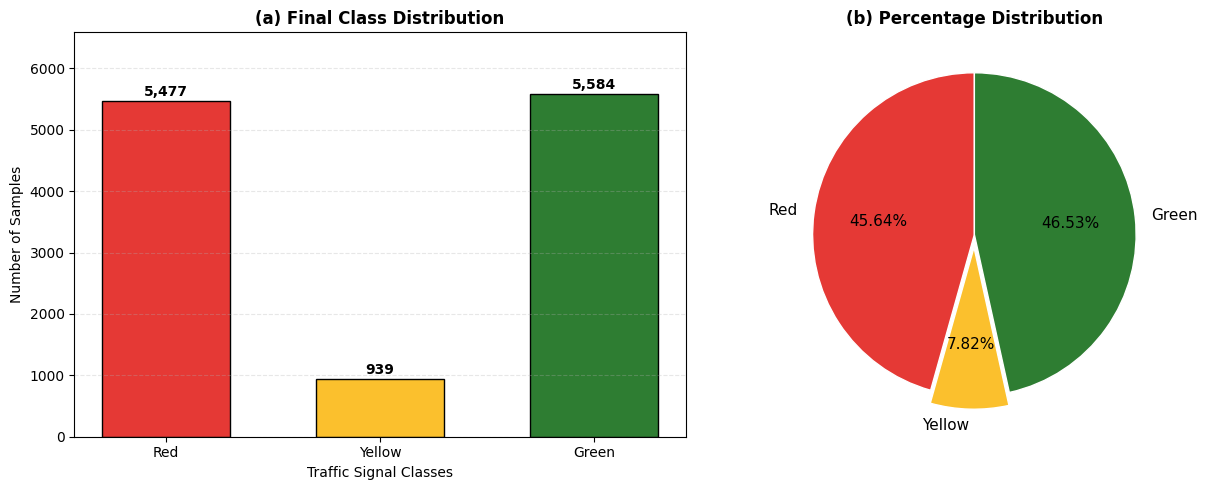

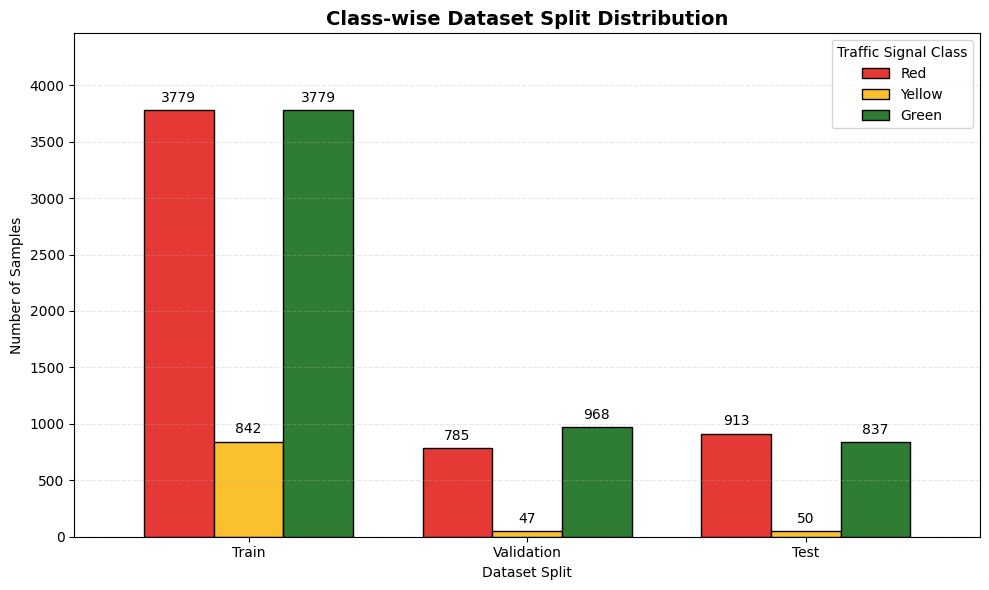


Final Dataset Visualization Completed!
All research figures and tables saved successfully!


In [16]:

# =============================================
# 13. FINAL DATASET DISTRIBUTION VISUALIZATION
# =============================================

class_order = ["Red", "Yellow", "Green"]
split_order = ["Train", "Validation", "Test"]

colors = ["#E53935", "#FBC02D", "#2E7D32"]

# Calculate final class distribution
final_counts = (
    valid_df["Class"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

# Calculate percentage
final_percentages = (
    final_counts / len(valid_df) * 100
)

# Create distribution table
final_distribution = pd.DataFrame({
    "Class": class_order,
    "Class ID": [0, 1, 2],
    "Images": final_counts.values,
    "Percentage (%)": final_percentages.round(2).values
})

print("FINAL DATASET DISTRIBUTION")
display(final_distribution)

# Create output directory
OUTPUT_DIR = Path("/kaggle/working/research_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Create figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

# ---------------------------------------------
# A. Final class distribution bar chart
# ---------------------------------------------

bars = axes[0].bar(
    class_order,
    final_counts.values,
    color=colors,
    edgecolor="black",
    width=0.6
)

axes[0].set_title(
    "(a) Final Class Distribution",
    fontweight="bold"
)

axes[0].set_xlabel("Traffic Signal Classes")
axes[0].set_ylabel("Number of Samples")

axes[0].set_ylim(
    0, final_counts.max() * 1.18
)

axes[0].grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

for bar, count in zip(bars, final_counts.values):

    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 80,
        f"{count:,}",
        ha="center",
        fontweight="bold"
    )

# ---------------------------------------------
# B. Final class percentage pie chart
# ---------------------------------------------

axes[1].pie(
    final_counts.values,
    labels=class_order,
    colors=colors,
    autopct="%1.2f%%",
    startangle=90,
    explode=(0, 0.08, 0),
    wedgeprops={"edgecolor": "white"},
    textprops={"fontsize": 11}
)

axes[1].set_title(
    "(b) Percentage Distribution",
    fontweight="bold"
)

plt.tight_layout()

# Save figures
fig.savefig(
    OUTPUT_DIR / "final_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "final_class_distribution.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ---------------------------------------------
# C. Class-wise dataset split visualization
# ---------------------------------------------

split_counts = pd.crosstab(
    valid_df["Class"],
    valid_df["Split"]
).reindex(
    index=class_order,
    columns=split_order,
    fill_value=0
)

fig, ax = plt.subplots(figsize=(10, 6))

split_counts.T.plot(
    kind="bar",
    color=colors,
    edgecolor="black",
    width=0.75,
    ax=ax
)

ax.set_title(
    "Class-wise Dataset Split Distribution",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Dataset Split")
ax.set_ylabel("Number of Samples")

ax.set_ylim(
    0, split_counts.to_numpy().max() * 1.18
)

ax.legend(title="Traffic Signal Class")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.xticks(rotation=0)

for container in ax.containers:

    ax.bar_label(
        container,
        padding=4,
        fontsize=10
    )

plt.tight_layout()

# Save split distribution figures
fig.savefig(
    OUTPUT_DIR / "dataset_split_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "dataset_split_distribution.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Save final tables
final_distribution.to_csv(
    OUTPUT_DIR / "final_class_distribution.csv",
    index=False
)

split_counts.to_csv(
    OUTPUT_DIR / "classwise_split_distribution.csv"
)

print("\nFinal Dataset Visualization Completed!")
print("All research figures and tables saved successfully!")


### 3.11 Sample Image Visualization

Representative images from the training dataset
are visualized alongside their corresponding
cropped traffic light regions using bounding box
coordinates.


Class: Red
Sequence: dayClip9
Original Image Shape: (960, 1280, 3)
Cropped Image Shape: (54, 33, 3)
Class ID: 0

Class: Yellow
Sequence: nightClip4
Original Image Shape: (960, 1280, 3)
Cropped Image Shape: (30, 13, 3)
Class ID: 1

Class: Green
Sequence: dayClip5
Original Image Shape: (960, 1280, 3)
Cropped Image Shape: (25, 15, 3)
Class ID: 2


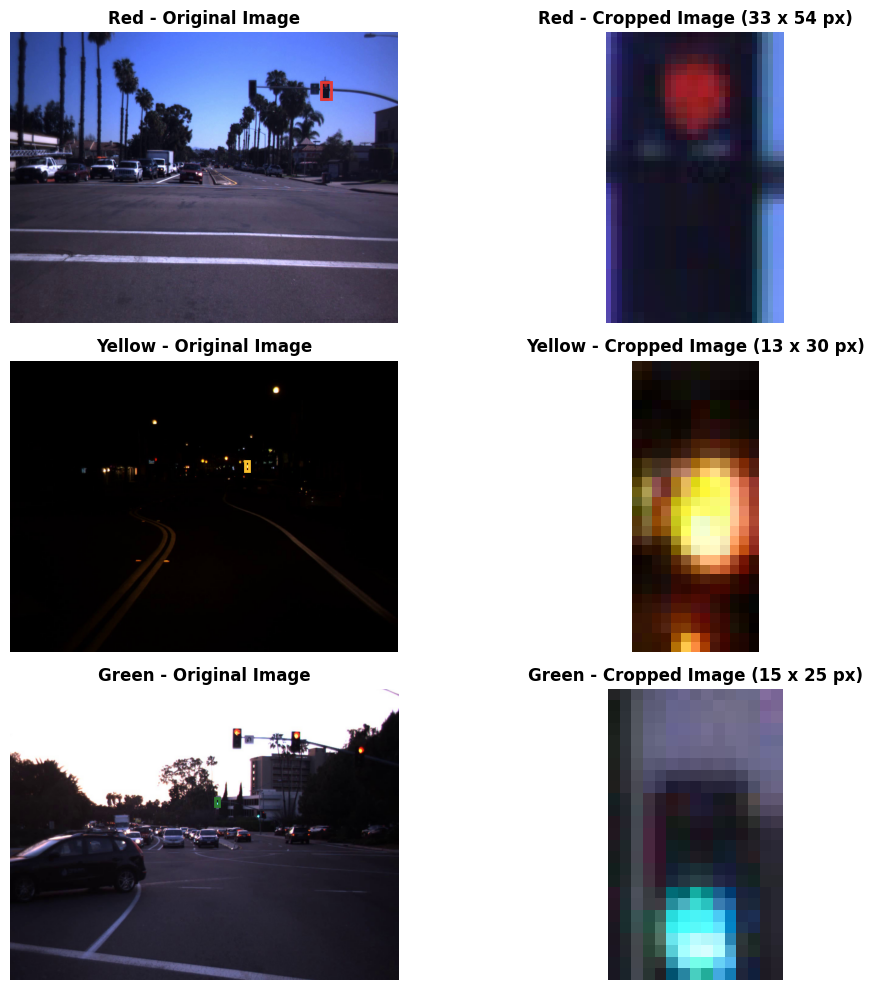


Sample Image Visualization Completed!
Research Figures Saved Successfully!


In [17]:

# =============================================
# 14. SAMPLE IMAGE VISUALIZATION
# =============================================

from matplotlib.patches import Rectangle

class_order = ["Red", "Yellow", "Green"]

class_colors = {
    "Red": "#E53935",
    "Yellow": "#FBC02D",
    "Green": "#2E7D32"
}

# Use training samples only
visualization_df = valid_df[
    valid_df["Split"] == "Train"
].copy()

# Create figure
fig, axes = plt.subplots(
    3, 2,
    figsize=(12, 10)
)

for i, class_name in enumerate(class_order):

    # Select one reproducible sample per class
    sample = visualization_df[
        visualization_df["Class"] == class_name
    ].sample(
        n=1,
        random_state=SEED
    ).iloc[0]

    # Read original image
    image = cv2.imread(str(sample["Image_Path"]))

    if image is None:
        raise ValueError("Unable to read sample image.")

    # Convert BGR to RGB
    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    # Extract bounding box coordinates
    x_min = int(sample["Upper left corner X"])
    y_min = int(sample["Upper left corner Y"])

    x_max = int(sample["Lower right corner X"])
    y_max = int(sample["Lower right corner Y"])

    # Crop traffic light
    cropped_image = image[
        y_min:y_max,
        x_min:x_max
    ]

    # Display original image
    axes[i, 0].imshow(image)

    # Draw bounding box
    bbox = Rectangle(
        (x_min, y_min),
        x_max - x_min,
        y_max - y_min,
        linewidth=2,
        edgecolor=class_colors[class_name],
        facecolor="none"
    )

    axes[i, 0].add_patch(bbox)

    axes[i, 0].set_title(
        f"{class_name} - Original Image",
        fontsize=12,
        fontweight="bold"
    )

    axes[i, 0].axis("off")

    # Display cropped image
    axes[i, 1].imshow(
        cropped_image,
        interpolation="nearest"
    )

    axes[i, 1].set_title(
        f"{class_name} - Cropped Image "
        f"({cropped_image.shape[1]} x "
        f"{cropped_image.shape[0]} px)",
        fontsize=12,
        fontweight="bold"
    )

    axes[i, 1].axis("off")

    # Display sample information
    print(f"\nClass: {class_name}")
    print("Sequence:", sample["Sequence"])
    print("Original Image Shape:", image.shape)
    print("Cropped Image Shape:", cropped_image.shape)
    print("Class ID:", sample["Label"])

plt.tight_layout()

# Save publication-quality figure
fig.savefig(
    OUTPUT_DIR / "sample_traffic_light_images.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "sample_traffic_light_images.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nSample Image Visualization Completed!")
print("Research Figures Saved Successfully!")


## 4. Image Preprocessing

### 4.1 Bounding Box-based Image Cropping
### 4.2 RGB Color Conversion
### 4.3 Aspect Ratio Preservation and Padding
### 4.4 Image Resizing (64 × 64 × 3)
### 4.5 Pixel Normalization

In [18]:

# =============================================
# 15. IMAGE PREPROCESSING CONFIGURATION
# =============================================

IMG_SIZE = 64
CHANNELS = 3
NUM_CLASSES = 3

CLASS_NAMES = ["Red", "Yellow", "Green"]

def resize_with_padding(image, target_size=64):

    height, width = image.shape[:2]

    # Calculate scaling factor
    scale = min(
        target_size / width,
        target_size / height
    )

    new_width = max(1, round(width * scale))
    new_height = max(1, round(height * scale))

    # Select interpolation method
    interpolation = (
        cv2.INTER_AREA
        if scale < 1
        else cv2.INTER_LINEAR
    )

    # Resize while preserving aspect ratio
    resized = cv2.resize(
        image,
        (new_width, new_height),
        interpolation=interpolation
    )

    # Create black background
    padded_image = np.zeros(
        (target_size, target_size, 3),
        dtype=np.uint8
    )

    # Calculate center position
    x_offset = (target_size - new_width) // 2
    y_offset = (target_size - new_height) // 2

    # Place resized image in the center
    padded_image[
        y_offset:y_offset + new_height,
        x_offset:x_offset + new_width
    ] = resized

    return padded_image


print("Target Image Size:", IMG_SIZE)
print("Number of Channels:", CHANNELS)
print("Number of Classes:", NUM_CLASSES)
print("Image Preprocessing Function Ready!")


Target Image Size: 64
Number of Channels: 3
Number of Classes: 3
Image Preprocessing Function Ready!


In [19]:

# =============================================
# 16. PREPROCESS ALL TRAFFIC LIGHT IMAGES
# =============================================

from tqdm.auto import tqdm

preprocess_df = valid_df.reset_index(drop=True).copy()

total_samples = len(preprocess_df)

# Allocate memory for images and labels
X = np.zeros(
    (total_samples, IMG_SIZE, IMG_SIZE, CHANNELS),
    dtype=np.uint8
)

y = preprocess_df["Label"].to_numpy(dtype=np.int32)

processed_count = 0

# Group by original image to avoid repeated reading
image_groups = preprocess_df.groupby(
    "Image_Path",
    sort=False
)

print("Total Samples:", total_samples)
print("Starting Image Preprocessing...\n")

for image_path, group in tqdm(
    image_groups,
    total=preprocess_df["Image_Path"].nunique(),
    desc="Preprocessing Images"
):

    # Read original image
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Unreadable image: {image_path}")

    for idx, row in group.iterrows():

        # Bounding box coordinates
        x_min = int(row["Upper left corner X"])
        y_min = int(row["Upper left corner Y"])

        x_max = int(row["Lower right corner X"])
        y_max = int(row["Lower right corner Y"])

        # Crop traffic light
        cropped = image[
            y_min:y_max,
            x_min:x_max
        ]

        if cropped.size == 0:
            raise ValueError(f"Empty crop at row {idx}")

        # Convert BGR to RGB
        cropped_rgb = cv2.cvtColor(
            cropped,
            cv2.COLOR_BGR2RGB
        )

        # Resize with aspect ratio preservation
        processed = resize_with_padding(
            cropped_rgb,
            IMG_SIZE
        )

        # Store processed image
        X[idx] = processed

        processed_count += 1

# Verify dataset
assert processed_count == total_samples
assert len(X) == len(y)

print("\n" + "=" * 60)
print("IMAGE PREPROCESSING RESULTS")
print("=" * 60)

print("Total Processed Images:", processed_count)
print("Image Array Shape:", X.shape)
print("Label Array Shape:", y.shape)
print("Image Data Type:", X.dtype)
print("Minimum Pixel Value:", X.min())
print("Maximum Pixel Value:", X.max())

print("\nImage Preprocessing Completed Successfully!")


Total Samples: 12000
Starting Image Preprocessing...



Preprocessing Images:   0%|          | 0/9623 [00:00<?, ?it/s]


IMAGE PREPROCESSING RESULTS
Total Processed Images: 12000
Image Array Shape: (12000, 64, 64, 3)
Label Array Shape: (12000,)
Image Data Type: uint8
Minimum Pixel Value: 0
Maximum Pixel Value: 255

Image Preprocessing Completed Successfully!


In [20]:

# =============================================
# 17. PIXEL NORMALIZATION AND DATASET PREPARATION
# =============================================

# Verify dataset alignment
assert len(X) == len(y) == len(preprocess_df)

# Normalize pixel values
X_normalized = X.astype(np.float32) / 255.0

# Use previously assigned dataset splits
train_mask = preprocess_df["Split"].eq("Train").to_numpy()

val_mask = preprocess_df["Split"].eq("Validation").to_numpy()

test_mask = preprocess_df["Split"].eq("Test").to_numpy()

# Prepare training dataset
X_train = X_normalized[train_mask]
y_train = y[train_mask]

# Prepare validation dataset
X_val = X_normalized[val_mask]
y_val = y[val_mask]

# Prepare testing dataset
X_test = X_normalized[test_mask]
y_test = y[test_mask]

# Verify dataset sizes
assert len(X_train) == 8400
assert len(X_val) == 1800
assert len(X_test) == 1800

assert len(X_train) + len(X_val) + len(X_test) == 12000

# Display results
print("=" * 60)
print("NORMALIZATION AND DATASET PREPARATION")
print("=" * 60)

print("\nTraining Dataset:")
print("X_train Shape:", X_train.shape)
print("y_train Shape:", y_train.shape)

print("\nValidation Dataset:")
print("X_val Shape:", X_val.shape)
print("y_val Shape:", y_val.shape)

print("\nTesting Dataset:")
print("X_test Shape:", X_test.shape)
print("y_test Shape:", y_test.shape)

print("\nNormalized Data Type:", X_normalized.dtype)
print("Minimum Pixel Value:", X_normalized.min())
print("Maximum Pixel Value:", X_normalized.max())

print("\nDataset Preparation Completed Successfully!")


NORMALIZATION AND DATASET PREPARATION

Training Dataset:
X_train Shape: (8400, 64, 64, 3)
y_train Shape: (8400,)

Validation Dataset:
X_val Shape: (1800, 64, 64, 3)
y_val Shape: (1800,)

Testing Dataset:
X_test Shape: (1800, 64, 64, 3)
y_test Shape: (1800,)

Normalized Data Type: float32
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0

Dataset Preparation Completed Successfully!


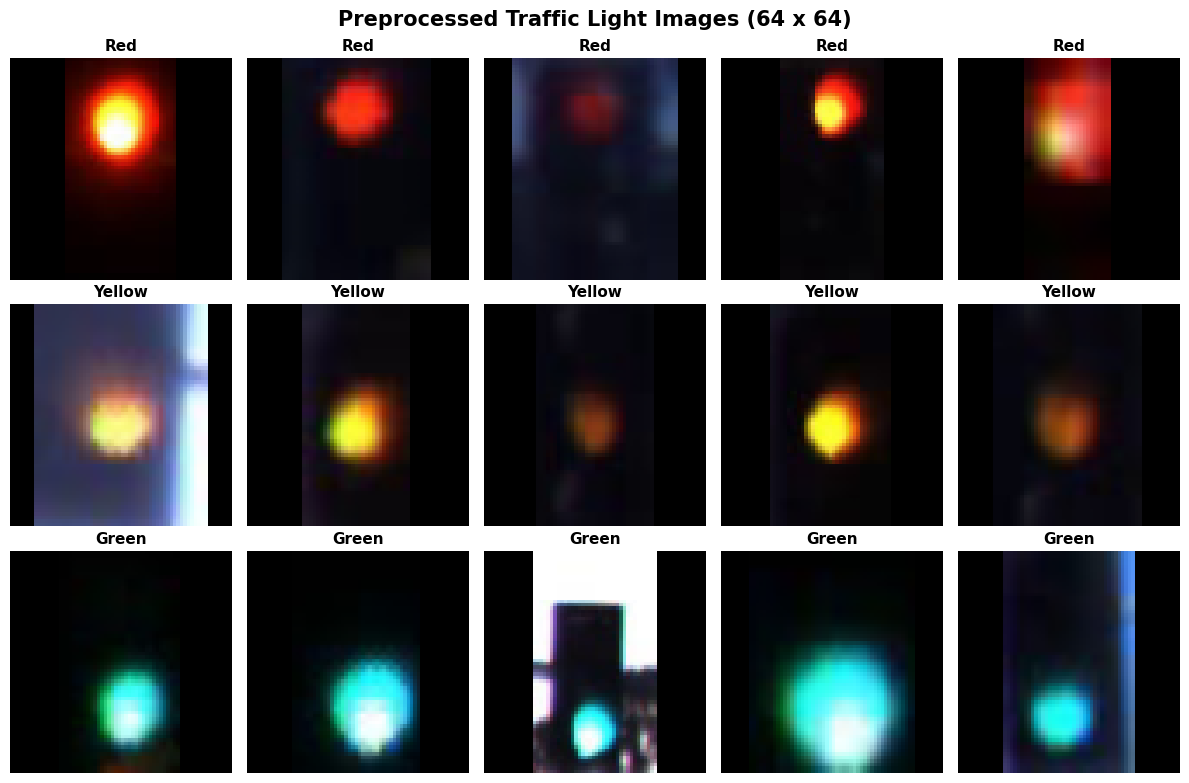

Preprocessed Sample Visualization Completed!


In [21]:

# =============================================
# 18. PREPROCESSED IMAGE VISUALIZATION
# =============================================

CLASS_NAMES = ["Red", "Yellow", "Green"]

rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(
    3, 5,
    figsize=(12, 8)
)

for class_id, class_name in enumerate(CLASS_NAMES):

    # Find training samples for each class
    indices = np.where(y_train == class_id)[0]

    # Select five random samples
    selected_indices = rng.choice(
        indices,
        size=5,
        replace=False
    )

    for j, idx in enumerate(selected_indices):

        axes[class_id, j].imshow(X_train[idx])

        axes[class_id, j].set_title(
            class_name,
            fontsize=11,
            fontweight="bold"
        )

        axes[class_id, j].axis("off")

fig.suptitle(
    "Preprocessed Traffic Light Images (64 x 64)",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

# Save research figure
fig.savefig(
    OUTPUT_DIR / "preprocessed_samples.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "preprocessed_samples.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Preprocessed Sample Visualization Completed!")


In [22]:

# =============================================
# 19. SAVE PREPROCESSED DATASET
# =============================================

DATA_OUTPUT = Path("/kaggle/working/preprocessed_dataset")

DATA_OUTPUT.mkdir(
    parents=True,
    exist_ok=True
)

# Save images and labels in compact uint8 format
# Normalization can be reapplied when loading

np.save(DATA_OUTPUT / "X_train.npy", X[train_mask])
np.save(DATA_OUTPUT / "y_train.npy", y_train)

np.save(DATA_OUTPUT / "X_val.npy", X[val_mask])
np.save(DATA_OUTPUT / "y_val.npy", y_val)

np.save(DATA_OUTPUT / "X_test.npy", X[test_mask])
np.save(DATA_OUTPUT / "y_test.npy", y_test)

# Save metadata for reproducibility
preprocess_df.to_csv(
    DATA_OUTPUT / "dataset_metadata.csv",
    index=False
)

print("=" * 60)
print("SAVED DATASET FILES")
print("=" * 60)

total_size = 0

for file in sorted(DATA_OUTPUT.iterdir()):

    size_mb = file.stat().st_size / (1024 ** 2)

    total_size += size_mb

    print(f"{file.name}: {size_mb:.2f} MB")

print(f"\nTotal Dataset Size: {total_size:.2f} MB")

print("\nPreprocessed Dataset Saved Successfully!")


SAVED DATASET FILES
X_test.npy: 21.09 MB
X_train.npy: 98.44 MB
X_val.npy: 21.09 MB
dataset_metadata.csv: 4.55 MB
y_test.npy: 0.01 MB
y_train.npy: 0.03 MB
y_val.npy: 0.01 MB

Total Dataset Size: 145.22 MB

Preprocessed Dataset Saved Successfully!


## 5. Data Augmentation and Class Imbalance Handling

### 5.1 Training Class Distribution
### 5.2 Class Weight Calculation
### 5.3 Data Augmentation Configuration
### 5.4 Augmented Image Visualization

In [23]:

# =============================================
# 20. CLASS WEIGHT CALCULATION
# =============================================

from sklearn.utils.class_weight import compute_class_weight

CLASS_NAMES = ["Red", "Yellow", "Green"]

classes = np.array([0, 1, 2])

# Calculate balanced class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

# Convert weights into dictionary
class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

# Calculate training class counts
training_counts = np.bincount(
    y_train,
    minlength=3
)

# Create research table
class_weight_table = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Class ID": classes,
    "Training Images": training_counts,
    "Class Weight": weights.round(4)
})

print("=" * 60)
print("CLASS WEIGHT CALCULATION")
print("=" * 60)

display(class_weight_table)

print("\nClass Weight Dictionary:")
print(class_weights)

# Save research table
class_weight_table.to_csv(
    OUTPUT_DIR / "class_weights.csv",
    index=False
)

print("\nClass Weight Calculation Completed!")


CLASS WEIGHT CALCULATION


,Class,Class ID,Training Images,Class Weight
0,Red,0,3779,0.7409
1,Yellow,1,842,3.3254
2,Green,2,3779,0.7409



Class Weight Dictionary:
{0: 0.7409367557554909, 1: 3.32541567695962, 2: 0.7409367557554909}

Class Weight Calculation Completed!


In [24]:

# =============================================
# 21. DATA AUGMENTATION CONFIGURATION
# =============================================

data_augmentation = keras.Sequential(
    [
        layers.RandomRotation(
            factor=0.03,
            fill_mode="constant",
            fill_value=0.0,
            seed=SEED
        ),

        layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="constant",
            fill_value=0.0,
            seed=SEED + 1
        ),

        layers.RandomZoom(
            height_factor=0.10,
            width_factor=0.10,
            fill_mode="constant",
            fill_value=0.0,
            seed=SEED + 2
        )
    ],
    name="data_augmentation"
)

print("Data Augmentation Configuration:")

data_augmentation.summary()

print("\nData Augmentation Ready!")


Data Augmentation Configuration:


Model: "data_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ ?                      │   0 (unbuilt) │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Data Augmentation Ready!


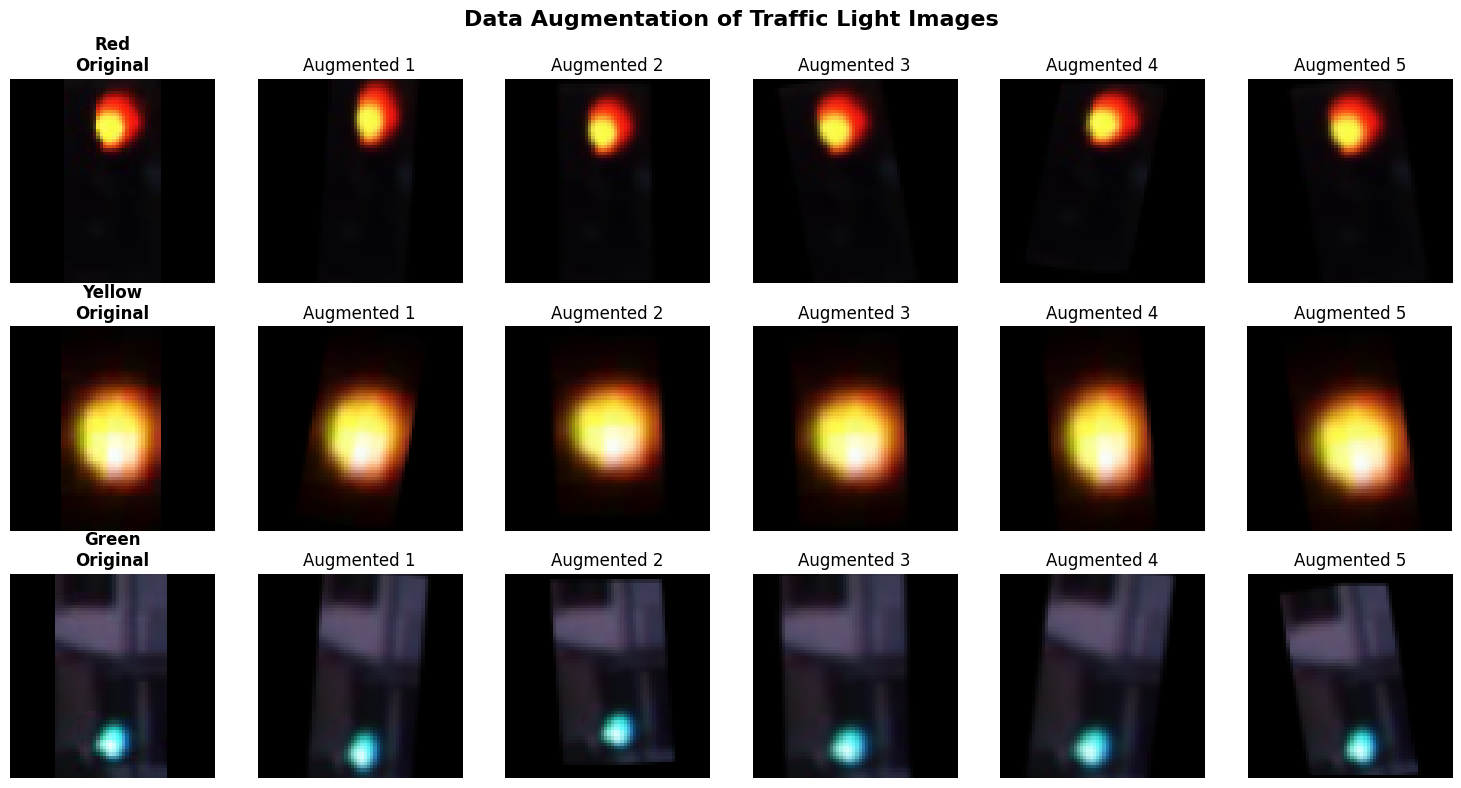

Data Augmentation Visualization Completed!
Research Figures Saved Successfully!


In [25]:

# =============================================
# 22. AUGMENTED IMAGE VISUALIZATION
# =============================================

rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(
    3, 6,
    figsize=(15, 8)
)

for class_id, class_name in enumerate(CLASS_NAMES):

    # Select one training image from each class
    indices = np.where(y_train == class_id)[0]

    sample_index = rng.choice(indices)

    original_image = X_train[sample_index]

    # Display original image
    axes[class_id, 0].imshow(original_image)

    axes[class_id, 0].set_title(
        f"{class_name}\nOriginal",
        fontweight="bold"
    )

    axes[class_id, 0].axis("off")

    # Generate five augmented versions
    for j in range(1, 6):

        augmented_image = data_augmentation(
            tf.expand_dims(original_image, axis=0),
            training=True
        )[0].numpy()

        augmented_image = np.clip(
            augmented_image,
            0.0,
            1.0
        )

        axes[class_id, j].imshow(
            augmented_image
        )

        axes[class_id, j].set_title(
            f"Augmented {j}"
        )

        axes[class_id, j].axis("off")

fig.suptitle(
    "Data Augmentation of Traffic Light Images",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Save research figures
fig.savefig(
    OUTPUT_DIR / "data_augmentation_samples.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "data_augmentation_samples.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Data Augmentation Visualization Completed!")
print("Research Figures Saved Successfully!")


## 6. CNN Model Architecture and Training

### 6.1 Data Leakage and Duplicate Image Audit
### 6.2 Basic CNN Architecture
### 6.3 Model Compilation
### 6.4 Model Training
### 6.5 Performance Evaluation

In [26]:

# =============================================
# 23. DATA LEAKAGE AND DUPLICATE IMAGE AUDIT
# =============================================

import hashlib

# Verify image and metadata alignment
assert len(X) == len(y) == len(preprocess_df)

audit_df = preprocess_df.copy().reset_index(drop=True)

# Generate a unique hash for each processed image
audit_df["Image_Hash"] = [
    hashlib.sha256(image.tobytes()).hexdigest()
    for image in X
]

# Create sets for each dataset split
split_names = ["Train", "Validation", "Test"]

hash_sets = {
    split: set(
        audit_df.loc[
            audit_df["Split"] == split,
            "Image_Hash"
        ]
    )
    for split in split_names
}

# Check identical image content across splits
train_val_overlap = (
    hash_sets["Train"] & hash_sets["Validation"]
)

train_test_overlap = (
    hash_sets["Train"] & hash_sets["Test"]
)

val_test_overlap = (
    hash_sets["Validation"] & hash_sets["Test"]
)

print("=" * 60)
print("DATA LEAKAGE AUDIT RESULTS")
print("=" * 60)

print("Total Images:", len(audit_df))

print("Unique Image Hashes:",
      audit_df["Image_Hash"].nunique())

print("Duplicate Images:",
      len(audit_df) - audit_df["Image_Hash"].nunique())

print("\nCROSS-SPLIT DUPLICATE CHECK")

print("Train-Validation Overlap:",
      len(train_val_overlap))

print("Train-Test Overlap:",
      len(train_test_overlap))

print("Validation-Test Overlap:",
      len(val_test_overlap))

# Collect overlapping hashes
overlapping_hashes = (
    train_val_overlap |
    train_test_overlap |
    val_test_overlap
)

# Check for identical images with different labels
conflicting_hashes = (
    audit_df.groupby("Image_Hash")["Label"]
    .nunique()
)

conflicting_hashes = conflicting_hashes[
    conflicting_hashes > 1
]

print("\nConflicting Label Groups:",
      len(conflicting_hashes))

# Save audit information
audit_df.to_csv(
    OUTPUT_DIR / "dataset_leakage_audit.csv",
    index=False
)

if not overlapping_hashes:

    print("\nNo exact image content overlap detected.")

else:

    print("\nWARNING: Cross-split duplicates detected!")

    duplicate_df = audit_df[
        audit_df["Image_Hash"].isin(
            overlapping_hashes
        )
    ]

    display(
        duplicate_df[
            ["Filename", "Class", "Sequence", "Split"]
        ].head(20)
    )

    duplicate_df.to_csv(
        OUTPUT_DIR / "cross_split_duplicates.csv",
        index=False
    )

print("\nData Leakage Audit Completed!")


DATA LEAKAGE AUDIT RESULTS
Total Images: 12000
Unique Image Hashes: 12000
Duplicate Images: 0

CROSS-SPLIT DUPLICATE CHECK
Train-Validation Overlap: 0
Train-Test Overlap: 0
Validation-Test Overlap: 0

Conflicting Label Groups: 0

No exact image content overlap detected.

Data Leakage Audit Completed!


### 6.2 Basic CNN Model Architecture

A baseline convolutional neural network was designed
using three convolutional layers, max-pooling layers,
a fully connected layer, dropout, and a Softmax
classification layer.

The baseline experiment excludes data augmentation
and class weighting to establish a reference
performance for subsequent experiments.

In [27]:

# =============================================
# 24. BASIC CNN MODEL ARCHITECTURE
# =============================================

# Set reproducibility seed
keras.utils.set_random_seed(SEED)

# Model configuration
IMG_SIZE = 64
NUM_CLASSES = 3
LEARNING_RATE = 0.001
BATCH_SIZE = 64
EPOCHS = 50

# Verify available GPUs
gpus = tf.config.list_physical_devices("GPU")

assert len(gpus) >= 1, "GPU is not available!"

print("Available GPUs:", len(gpus))

# Multi-GPU distribution strategy
strategy = tf.distribute.MirroredStrategy()

print("Number of Replicas:",
      strategy.num_replicas_in_sync)

# Build reusable CNN model
def build_basic_cnn():

    model = keras.Sequential([

        # Input layer
        layers.Input(shape=(64, 64, 3)),

        # Convolution Block 1
        layers.Conv2D(
            32,
            (3, 3),
            activation="relu",
            padding="same",
            name="conv1"
        ),

        layers.MaxPooling2D(
            pool_size=(2, 2),
            name="pool1"
        ),

        # Convolution Block 2
        layers.Conv2D(
            64,
            (3, 3),
            activation="relu",
            padding="same",
            name="conv2"
        ),

        layers.MaxPooling2D(
            pool_size=(2, 2),
            name="pool2"
        ),

        # Convolution Block 3
        layers.Conv2D(
            128,
            (3, 3),
            activation="relu",
            padding="same",
            name="conv3"
        ),

        layers.MaxPooling2D(
            pool_size=(2, 2),
            name="pool3"
        ),

        # Flatten feature maps
        layers.Flatten(name="flatten"),

        # Fully connected layer
        layers.Dense(
            128,
            activation="relu",
            name="dense1"
        ),

        # Dropout regularization
        layers.Dropout(
            0.3,
            name="dropout"
        ),

        # Output classification layer
        layers.Dense(
            NUM_CLASSES,
            activation="softmax",
            name="output"
        )

    ], name="Basic_CNN")

    return model


# Build and compile model using both GPUs
with strategy.scope():

    basic_cnn = build_basic_cnn()

    basic_cnn.compile(

        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]
    )

# Display model architecture
print("\n" + "=" * 60)
print("BASIC CNN MODEL SUMMARY")
print("=" * 60)

basic_cnn.summary()

print("\nTotal Parameters:",
      basic_cnn.count_params())

print("\nBasic CNN Model Created Successfully!")
print("Model Compilation Completed!")


Available GPUs: 2
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Number of Replicas: 2

BASIC CNN MODEL SUMMARY


Model: "Basic_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,339 (4.36 MB)

 Trainable params: 1,142,339 (4.36 MB)

 Non-trainable params: 0 (0.00 B)


Total Parameters: 1142339

Basic CNN Model Created Successfully!
Model Compilation Completed!


CNN Architecture Diagram Saved!


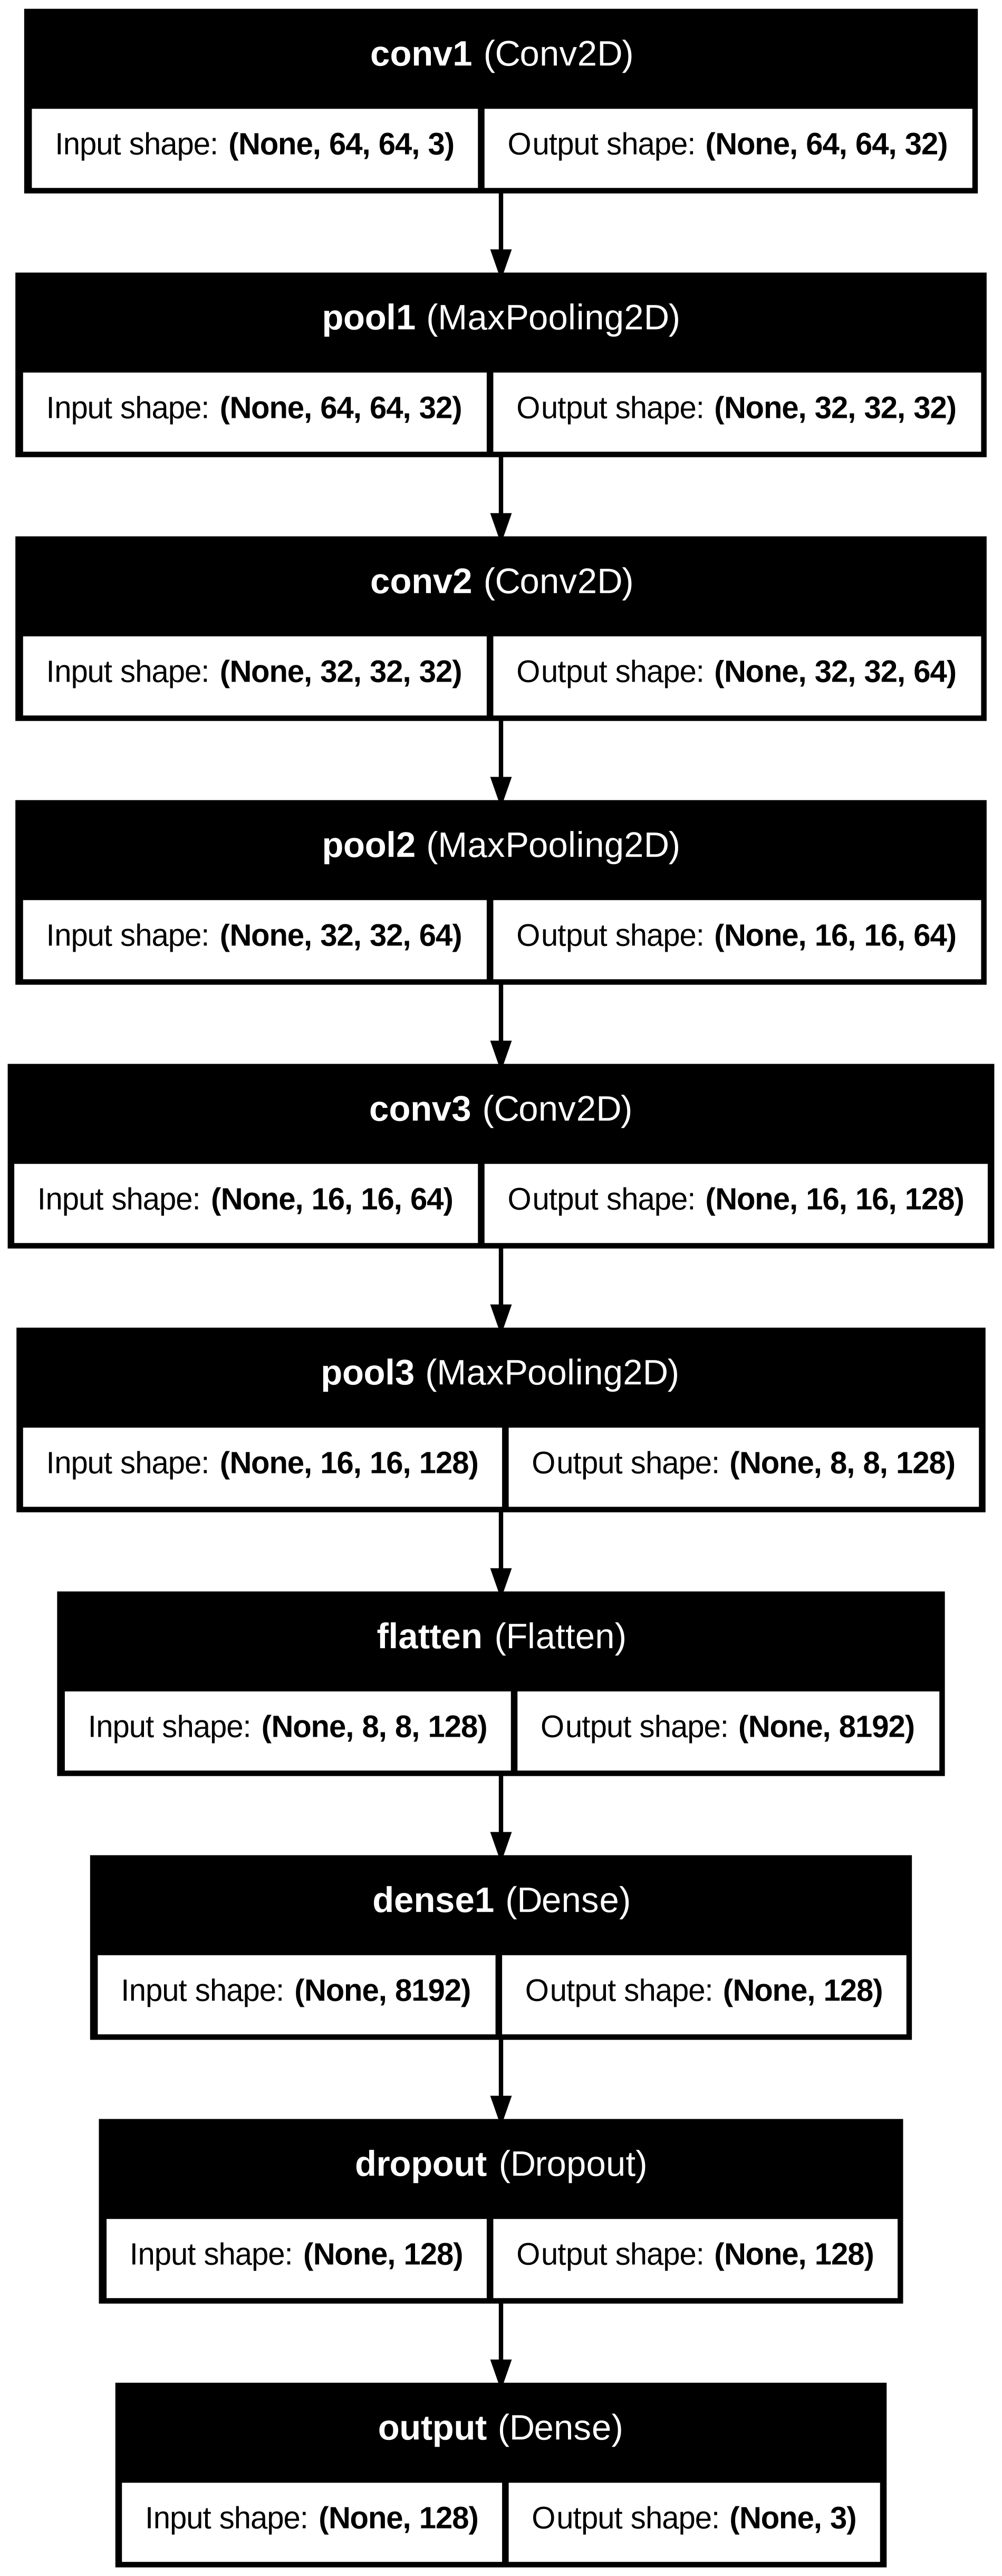


Model Architecture Saving Completed!


In [28]:

# =============================================
# 25. SAVE CNN MODEL ARCHITECTURE
# =============================================

MODEL_DIR = Path("/kaggle/working/saved_models")

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save model summary
with open(
    OUTPUT_DIR / "basic_cnn_summary.txt",
    "w"
) as file:

    basic_cnn.summary(
        print_fn=lambda line: file.write(line + "\n")
    )

# Save model architecture as JSON
with open(
    OUTPUT_DIR / "basic_cnn_architecture.json",
    "w"
) as file:

    file.write(basic_cnn.to_json())

# Generate CNN architecture diagram
try:

    keras.utils.plot_model(
        basic_cnn,
        to_file=str(
            OUTPUT_DIR / "basic_cnn_architecture.png"
        ),
        show_shapes=True,
        show_layer_names=True,
        show_dtype=False,
        rankdir="TB",
        dpi=300
    )

    print("CNN Architecture Diagram Saved!")

    from IPython.display import Image, display

    display(
        Image(
            filename=str(
                OUTPUT_DIR /
                "basic_cnn_architecture.png"
            )
        )
    )

except Exception as error:

    print("Architecture plotting unavailable:", error)
    print("Model summary and JSON are still saved.")

print("\nModel Architecture Saving Completed!")


### 6.3 Baseline CNN Model Training (EXP-01)

The baseline CNN model is trained using the Adam
optimizer with an initial learning rate of 0.001,
a batch size of 64, and a maximum of 50 epochs.

Early stopping, model checkpointing, and adaptive
learning rate reduction are employed to optimize
the training process.

Data augmentation and class weighting are excluded
from this baseline experiment.

In [29]:

# =============================================
# 26. TRAINING CONFIGURATION AND CALLBACKS
# =============================================

import time

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    CSVLogger
)

# Training configuration
BATCH_SIZE = 64
EPOCHS = 50

EXPERIMENT_NAME = "EXP_01_Basic_CNN"

MODEL_DIR = Path("/kaggle/working/saved_models")

MODEL_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Verify multi-GPU configuration
print("Available GPUs:",
      len(tf.config.list_physical_devices("GPU")))

print("Number of Replicas:",
      strategy.num_replicas_in_sync)

# Prepare TensorFlow training datasets
with tf.device("/CPU:0"):

    train_dataset = (
        tf.data.Dataset
        .from_tensor_slices((X_train, y_train))
        .shuffle(
            buffer_size=len(X_train),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )

    val_dataset = (
        tf.data.Dataset
        .from_tensor_slices((X_val, y_val))
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )

# Best model saving path
checkpoint_path = MODEL_DIR / "basic_cnn_best.keras"

# Configure callbacks
callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    CSVLogger(
        filename=str(
            OUTPUT_DIR / "basic_cnn_training_log.csv"
        ),
        append=False
    )
]

print("\nTraining Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Batch Size:", BATCH_SIZE)
print("Maximum Epochs:", EPOCHS)

print("\nTraining Configuration Completed!")


Available GPUs: 2
Number of Replicas: 2

Training Samples: 8400
Validation Samples: 1800
Batch Size: 64
Maximum Epochs: 50

Training Configuration Completed!


In [30]:

# =============================================
# 27. BASELINE CNN MODEL TRAINING
# =============================================

print("=" * 60)
print("EXPERIMENT 01: BASELINE CNN")
print("=" * 60)

print("\nStarting CNN Model Training...\n")

# Record training start time
start_time = time.perf_counter()

# Train baseline CNN
history_basic = basic_cnn.fit(

    train_dataset,

    validation_data=val_dataset,

    epochs=EPOCHS,

    callbacks=callbacks,

    verbose=1

)

# Calculate total training time
end_time = time.perf_counter()

training_time_basic = end_time - start_time

# Convert training history into DataFrame
history_basic_df = pd.DataFrame(
    history_basic.history
)

history_basic_df.index += 1
history_basic_df.index.name = "Epoch"

# Save training history
history_basic_df.to_csv(
    OUTPUT_DIR / "basic_cnn_training_history.csv"
)

# Find best validation loss epoch
best_epoch = int(
    np.argmin(
        history_basic.history["val_loss"]
    ) + 1
)

best_result = history_basic_df.loc[best_epoch]

# Save experiment summary
experiment_summary = pd.DataFrame([{
    "Experiment": EXPERIMENT_NAME,
    "Model": "Basic CNN",
    "Total Parameters": basic_cnn.count_params(),
    "Completed Epochs": len(history_basic_df),
    "Best Epoch": best_epoch,
    "Training Accuracy": best_result["accuracy"],
    "Validation Accuracy": best_result["val_accuracy"],
    "Training Loss": best_result["loss"],
    "Validation Loss": best_result["val_loss"],
    "Training Time (Seconds)": training_time_basic
}])

experiment_summary.to_csv(
    OUTPUT_DIR / "basic_cnn_experiment_summary.csv",
    index=False
)

# Display training summary
print("\n" + "=" * 60)
print("BASELINE CNN TRAINING RESULTS")
print("=" * 60)

print("Completed Epochs:",
      len(history_basic_df))

print("Best Epoch:", best_epoch)

print(
    f"Training Accuracy at Best Epoch: "
    f"{best_result['accuracy'] * 100:.2f}%"
)

print(
    f"Validation Accuracy at Best Epoch: "
    f"{best_result['val_accuracy'] * 100:.2f}%"
)

print(
    f"Best Validation Loss: "
    f"{best_result['val_loss']:.6f}"
)

print(
    f"Total Training Time: "
    f"{training_time_basic:.2f} seconds"
)

print(
    f"Total Training Time: "
    f"{training_time_basic / 60:.2f} minutes"
)

display(experiment_summary)

print("\nBest Model Saved:", checkpoint_path)

print("\nBaseline CNN Training Completed Successfully!")


EXPERIMENT 01: BASELINE CNN

Starting CNN Model Training...

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:loc

,Experiment,Model,Total Parameters,Completed Epochs,Best Epoch,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss,Training Time (Seconds)
0,EXP_01_Basic_CNN,Basic CNN,1142339,7,2,0.997381,1.0,0.012773,0.000524,31.951005



Best Model Saved: /kaggle/working/saved_models/basic_cnn_best.keras

Baseline CNN Training Completed Successfully!


### 6.5 Training and Validation Performance

The learning behavior of the baseline CNN is
analyzed using training and validation accuracy
and loss curves. The optimal model checkpoint
is selected based on the minimum validation loss.

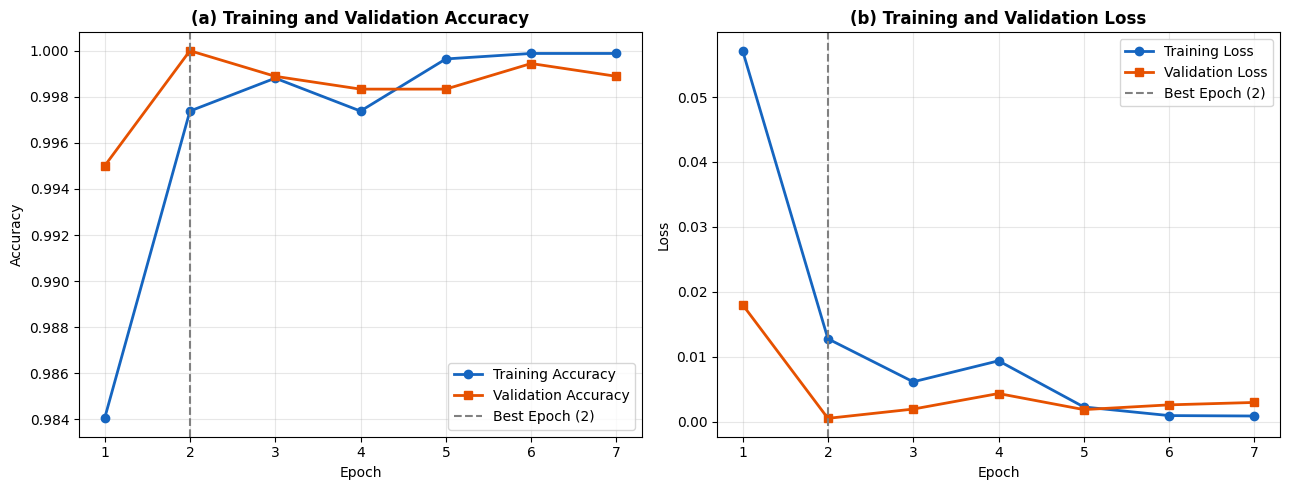

Accuracy and Loss Curves Saved Successfully!


In [31]:

# =============================================
# 28. BASELINE CNN ACCURACY AND LOSS CURVES
# =============================================

epochs = np.arange(1, len(history_basic_df) + 1)

best_epoch = int(
    history_basic_df["val_loss"].idxmin()
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

# ---------------------------------------------
# A. Accuracy curve
# ---------------------------------------------

axes[0].plot(
    epochs,
    history_basic_df["accuracy"],
    marker="o",
    color="#1565C0",
    linewidth=2,
    label="Training Accuracy"
)

axes[0].plot(
    epochs,
    history_basic_df["val_accuracy"],
    marker="s",
    color="#E65100",
    linewidth=2,
    label="Validation Accuracy"
)

axes[0].axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

axes[0].set_title(
    "(a) Training and Validation Accuracy",
    fontweight="bold"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_xticks(epochs)
axes[0].legend()
axes[0].grid(alpha=0.3)

# ---------------------------------------------
# B. Loss curve
# ---------------------------------------------

axes[1].plot(
    epochs,
    history_basic_df["loss"],
    marker="o",
    color="#1565C0",
    linewidth=2,
    label="Training Loss"
)

axes[1].plot(
    epochs,
    history_basic_df["val_loss"],
    marker="s",
    color="#E65100",
    linewidth=2,
    label="Validation Loss"
)

axes[1].axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

axes[1].set_title(
    "(b) Training and Validation Loss",
    fontweight="bold"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_xticks(epochs)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

# Save publication-quality figures
fig.savefig(
    OUTPUT_DIR / "basic_cnn_accuracy_loss.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "basic_cnn_accuracy_loss.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Accuracy and Loss Curves Saved Successfully!")


In [32]:

# =============================================
# 29. BASELINE CNN VALIDATION EVALUATION
# =============================================

CLASS_NAMES = ["Red", "Yellow", "Green"]

# Use the restored best model
val_loss, val_accuracy = basic_cnn.evaluate(
    val_dataset,
    verbose=0
)

# Generate validation predictions
y_val_prob = basic_cnn.predict(
    val_dataset,
    verbose=1
)

# Convert probabilities to predicted labels
y_val_pred = np.argmax(
    y_val_prob,
    axis=1
)

assert len(y_val_pred) == len(y_val)

# Calculate evaluation metrics
basic_accuracy = accuracy_score(
    y_val,
    y_val_pred
)

basic_precision = precision_score(
    y_val,
    y_val_pred,
    average="macro",
    zero_division=0
)

basic_recall = recall_score(
    y_val,
    y_val_pred,
    average="macro",
    zero_division=0
)

basic_f1 = f1_score(
    y_val,
    y_val_pred,
    average="macro",
    zero_division=0
)

basic_weighted_f1 = f1_score(
    y_val,
    y_val_pred,
    average="weighted",
    zero_division=0
)

# Display performance results
print("\n" + "=" * 60)
print("BASELINE CNN VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy: {basic_accuracy * 100:.4f}%")
print(f"Macro Precision: {basic_precision:.4f}")
print(f"Macro Recall: {basic_recall:.4f}")
print(f"Macro F1-score: {basic_f1:.4f}")
print(f"Weighted F1-score: {basic_weighted_f1:.4f}")
print(f"Validation Loss: {val_loss:.6f}")

print("\nCorrect Predictions:",
      np.sum(y_val == y_val_pred))

print("Incorrect Predictions:",
      np.sum(y_val != y_val_pred))

# Create evaluation table
basic_metrics = pd.DataFrame([{
    "Model": "Basic CNN",
    "Evaluation Split": "Validation",
    "Accuracy (%)": basic_accuracy * 100,
    "Macro Precision": basic_precision,
    "Macro Recall": basic_recall,
    "Macro F1-score": basic_f1,
    "Weighted F1-score": basic_weighted_f1,
    "Validation Loss": val_loss
}])

display(basic_metrics)

# Save evaluation results
basic_metrics.to_csv(
    OUTPUT_DIR / "basic_cnn_validation_metrics.csv",
    index=False
)

print("\nValidation Evaluation Completed!")


29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step

BASELINE CNN VALIDATION RESULTS
Accuracy: 100.0000%
Macro Precision: 1.0000
Macro Recall: 1.0000
Macro F1-score: 1.0000
Weighted F1-score: 1.0000
Validation Loss: 0.000524

Correct Predictions: 1800
Incorrect Predictions: 0


,Model,Evaluation Split,Accuracy (%),Macro Precision,Macro Recall,Macro F1-score,Weighted F1-score,Validation Loss
0,Basic CNN,Validation,100.0,1.0,1.0,1.0,1.0,0.000524



Validation Evaluation Completed!


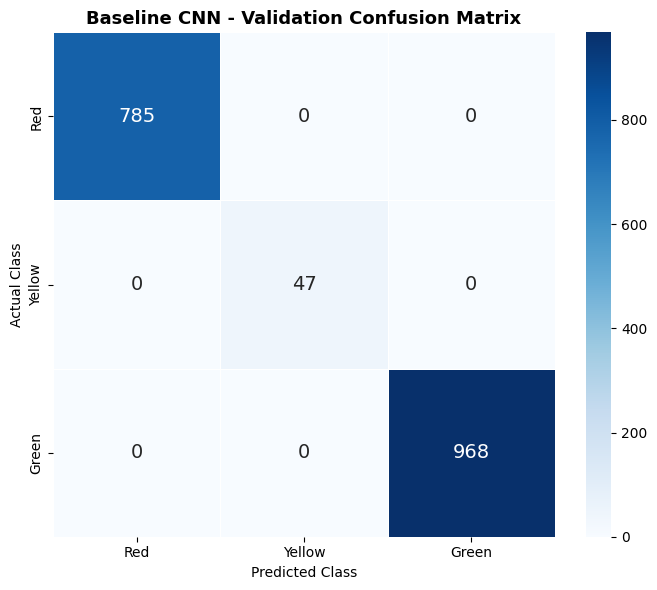


BASELINE CNN CLASSIFICATION REPORT


,precision,recall,f1-score,support
Red,1.0,1.0,1.0,785.0
Yellow,1.0,1.0,1.0,47.0
Green,1.0,1.0,1.0,968.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,1800.0
weighted avg,1.0,1.0,1.0,1800.0



Confusion Matrix Saved Successfully!
Classification Report Saved Successfully!
Baseline CNN Validation Analysis Completed!


In [33]:

# =============================================
# 30. CONFUSION MATRIX AND CLASSIFICATION REPORT
# =============================================

# Generate confusion matrix
cm_basic = confusion_matrix(
    y_val,
    y_val_pred,
    labels=[0, 1, 2]
)

# Create confusion matrix figure
fig, ax = plt.subplots(
    figsize=(7, 6)
)

sns.heatmap(
    cm_basic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    linewidths=0.5,
    annot_kws={"size": 14},
    ax=ax
)

ax.set_title(
    "Baseline CNN - Validation Confusion Matrix",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

plt.tight_layout()

# Save confusion matrix
fig.savefig(
    OUTPUT_DIR / "basic_cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "basic_cnn_confusion_matrix.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Generate classification report
report_basic = classification_report(
    y_val,
    y_val_pred,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_basic_df = pd.DataFrame(
    report_basic
).transpose()

print("\nBASELINE CNN CLASSIFICATION REPORT")

display(report_basic_df.round(4))

# Save classification report
report_basic_df.to_csv(
    OUTPUT_DIR / "basic_cnn_classification_report.csv"
)

# Save confusion matrix values
pd.DataFrame(
    cm_basic,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    OUTPUT_DIR / "basic_cnn_confusion_matrix.csv"
)

print("\nConfusion Matrix Saved Successfully!")
print("Classification Report Saved Successfully!")
print("Baseline CNN Validation Analysis Completed!")


## 7. CNN Model Improvement Experiments

### 7.1 Basic CNN with Data Augmentation (EXP-02)

This experiment investigates the effect of spatial
data augmentation on CNN classification performance
while maintaining the baseline model architecture
and training configuration.

Data augmentation is applied exclusively to the
training samples.

In [34]:

# =============================================
# 31. BASIC CNN WITH DATA AUGMENTATION
# =============================================

keras.utils.set_random_seed(SEED)

# Build a new model using both GPUs
with strategy.scope():

    # Create a fresh augmentation layer
    augmentation_exp02 = keras.models.clone_model(
        data_augmentation
    )

    # Create a fresh CNN
    cnn_exp02 = build_basic_cnn()

    # Combine augmentation and CNN
    augmented_cnn = keras.Sequential(
        [
            layers.Input(shape=(64, 64, 3)),
            augmentation_exp02,
            cnn_exp02
        ],
        name="CNN_With_Augmentation"
    )

    # Compile model
    augmented_cnn.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

print("=" * 60)
print("EXP-02 MODEL ARCHITECTURE")
print("=" * 60)

augmented_cnn.summary()

print("\nTotal Parameters:",
      augmented_cnn.count_params())

print("Number of GPU Replicas:",
      strategy.num_replicas_in_sync)

print("\nAugmented CNN Model Created Successfully!")


EXP-02 MODEL ARCHITECTURE


Model: "CNN_With_Augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Basic_CNN (Sequential)          │ (None, 3)              │     1,142,339 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,339 (4.36 MB)

 Trainable params: 1,142,339 (4.36 MB)

 Non-trainable params: 0 (0.00 B)


Total Parameters: 1142339
Number of GPU Replicas: 2

Augmented CNN Model Created Successfully!


In [35]:

# =============================================
# 32. TRAIN CNN WITH DATA AUGMENTATION
# =============================================

# Create a fresh training dataset
with tf.device("/CPU:0"):

    train_dataset_exp02 = (
        tf.data.Dataset
        .from_tensor_slices((X_train, y_train))
        .shuffle(
            buffer_size=len(X_train),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )

# Model checkpoint path
augmented_checkpoint = (
    MODEL_DIR / "augmented_cnn_best.keras"
)

# Fresh callbacks
callbacks_exp02 = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(augmented_checkpoint),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    CSVLogger(
        filename=str(
            OUTPUT_DIR /
            "augmented_cnn_training_log.csv"
        ),
        append=False
    )
]

print("=" * 60)
print("EXPERIMENT 02: CNN WITH DATA AUGMENTATION")
print("=" * 60)

start_time = time.perf_counter()

# Train the model
history_augmented = augmented_cnn.fit(

    train_dataset_exp02,

    validation_data=val_dataset,

    epochs=EPOCHS,

    callbacks=callbacks_exp02,

    verbose=1
)

# Calculate training time
training_time_augmented = (
    time.perf_counter() - start_time
)

# Convert history into DataFrame
history_augmented_df = pd.DataFrame(
    history_augmented.history
)

history_augmented_df.index += 1
history_augmented_df.index.name = "Epoch"

# Save training history
history_augmented_df.to_csv(
    OUTPUT_DIR /
    "augmented_cnn_training_history.csv"
)

# Identify best epoch
best_epoch_augmented = int(
    history_augmented_df["val_loss"].idxmin()
)

best_result_augmented = history_augmented_df.loc[
    best_epoch_augmented
]

# Create experiment summary
augmented_summary = pd.DataFrame([{
    "Experiment": "EXP_02_CNN_Augmentation",
    "Model": "CNN with Augmentation",
    "Total Parameters": augmented_cnn.count_params(),
    "Completed Epochs": len(history_augmented_df),
    "Best Epoch": best_epoch_augmented,
    "Training Accuracy": best_result_augmented["accuracy"],
    "Validation Accuracy": best_result_augmented["val_accuracy"],
    "Training Loss": best_result_augmented["loss"],
    "Validation Loss": best_result_augmented["val_loss"],
    "Training Time (Seconds)": training_time_augmented
}])

# Save experiment summary
augmented_summary.to_csv(
    OUTPUT_DIR /
    "augmented_cnn_experiment_summary.csv",
    index=False
)

# Display results
print("\n" + "=" * 60)
print("EXP-02 TRAINING RESULTS")
print("=" * 60)

print("Completed Epochs:",
      len(history_augmented_df))

print("Best Epoch:", best_epoch_augmented)

print(
    f"Training Accuracy: "
    f"{best_result_augmented['accuracy'] * 100:.2f}%"
)

print(
    f"Validation Accuracy: "
    f"{best_result_augmented['val_accuracy'] * 100:.2f}%"
)

print(
    f"Best Validation Loss: "
    f"{best_result_augmented['val_loss']:.6f}"
)

print(
    f"Training Time: "
    f"{training_time_augmented:.2f} seconds"
)

display(augmented_summary)

print("\nBest Model Saved:", augmented_checkpoint)

print("\nEXP-02 Training Completed Successfully!")


EXPERIMENT 02: CNN WITH DATA AUGMENTATION
Epoch 1/50
INFO:tensorflow:Collective all_reduce tensors: 10 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
128/132 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9364 - loss: 0.1913
Epoch 1: val_loss improved from None to 0.04552, saving model to /kaggle/working/saved_models/augmented_cnn_best.keras

Epoch 1: finished saving model to /kaggle/working/saved_models/augmented_cnn_best.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.9827 - loss: 0.0641 - val_accuracy: 0.9894 - val_loss: 0.0455 - learning_rate: 0.0010
Epoch 2/50
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9960 - loss: 0.0189
Epoch 2: val_loss improved from 0.04552 to 0.00090, saving model to /kaggle/working/saved_models/augmented_cnn_best.keras

Epoch 2: finished saving model to /kaggle/working/saved_models/augmented_cnn_best.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9964 -

,Experiment,Model,Total Parameters,Completed Epochs,Best Epoch,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss,Training Time (Seconds)
0,EXP_02_CNN_Augmentation,CNN with Augmentation,1142339,9,4,0.998929,1.0,0.004778,0.000284,35.751035



Best Model Saved: /kaggle/working/saved_models/augmented_cnn_best.keras

EXP-02 Training Completed Successfully!


In [36]:

# =============================================
# 33. EXP-02 VALIDATION EVALUATION
# =============================================

# Evaluate restored best model
aug_val_loss, aug_val_acc = augmented_cnn.evaluate(
    val_dataset,
    verbose=0
)

# Generate predictions
y_val_prob_augmented = augmented_cnn.predict(
    val_dataset,
    verbose=0
)

y_val_pred_augmented = np.argmax(
    y_val_prob_augmented,
    axis=1
)

assert len(y_val_pred_augmented) == len(y_val)

# Calculate metrics
augmented_metrics = pd.DataFrame([{

    "Model": "CNN with Augmentation",

    "Evaluation Split": "Validation",

    "Accuracy (%)": accuracy_score(
        y_val, y_val_pred_augmented
    ) * 100,

    "Macro Precision": precision_score(
        y_val, y_val_pred_augmented,
        average="macro",
        zero_division=0
    ),

    "Macro Recall": recall_score(
        y_val, y_val_pred_augmented,
        average="macro",
        zero_division=0
    ),

    "Macro F1-score": f1_score(
        y_val, y_val_pred_augmented,
        average="macro",
        zero_division=0
    ),

    "Weighted F1-score": f1_score(
        y_val, y_val_pred_augmented,
        average="weighted",
        zero_division=0
    ),

    "Validation Loss": aug_val_loss

}])

print("EXP-02 VALIDATION RESULTS")

display(augmented_metrics)

# Save metrics
augmented_metrics.to_csv(
    OUTPUT_DIR /
    "augmented_cnn_validation_metrics.csv",
    index=False
)

# Classification report
report_augmented = classification_report(
    y_val,
    y_val_pred_augmented,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_augmented_df = pd.DataFrame(
    report_augmented
).transpose()

print("\nCLASSIFICATION REPORT")

display(report_augmented_df.round(4))

report_augmented_df.to_csv(
    OUTPUT_DIR /
    "augmented_cnn_classification_report.csv"
)

# Compare baseline and augmented CNN
comparison_df = pd.concat(
    [basic_metrics, augmented_metrics],
    ignore_index=True
)

print("\nMODEL PERFORMANCE COMPARISON")

display(comparison_df.round(6))

comparison_df.to_csv(
    OUTPUT_DIR /
    "model_comparison_validation.csv",
    index=False
)

print("\nEXP-02 Evaluation Completed!")


EXP-02 VALIDATION RESULTS


,Model,Evaluation Split,Accuracy (%),Macro Precision,Macro Recall,Macro F1-score,Weighted F1-score,Validation Loss
0,CNN with Augmentation,Validation,100.0,1.0,1.0,1.0,1.0,0.000284



CLASSIFICATION REPORT


,precision,recall,f1-score,support
Red,1.0,1.0,1.0,785.0
Yellow,1.0,1.0,1.0,47.0
Green,1.0,1.0,1.0,968.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,1800.0
weighted avg,1.0,1.0,1.0,1800.0



MODEL PERFORMANCE COMPARISON


,Model,Evaluation Split,Accuracy (%),Macro Precision,Macro Recall,Macro F1-score,Weighted F1-score,Validation Loss
0,Basic CNN,Validation,100.0,1.0,1.0,1.0,1.0,0.000524
1,CNN with Augmentation,Validation,100.0,1.0,1.0,1.0,1.0,0.000284



EXP-02 Evaluation Completed!


### 7.4 Basic CNN with Class Weight (EXP-03)

This experiment investigates the effect of
class weighting on traffic light classification
performance, particularly for the minority
Yellow class.

The baseline CNN architecture is retained,
while balanced class weights are introduced
during model training.

In [37]:

# =============================================
# 34. BASIC CNN WITH CLASS WEIGHT
# =============================================

# Reset random seed
keras.utils.set_random_seed(SEED)

# Build a fresh CNN model using both GPUs
with strategy.scope():

    weighted_cnn = build_basic_cnn()

    weighted_cnn.compile(

        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]
    )

print("=" * 60)
print("EXP-03 MODEL CONFIGURATION")
print("=" * 60)

print("Total Parameters:",
      weighted_cnn.count_params())

print("Number of GPU Replicas:",
      strategy.num_replicas_in_sync)

print("\nClass Weights:")

for class_id, weight in class_weights.items():

    print(
        f"{CLASS_NAMES[class_id]}: "
        f"{weight:.4f}"
    )

print("\nData Augmentation: Disabled")
print("Class Weight: Enabled")

weighted_cnn.summary()

print("\nWeighted CNN Model Created Successfully!")


EXP-03 MODEL CONFIGURATION
Total Parameters: 1142339
Number of GPU Replicas: 2

Class Weights:
Red: 0.7409
Yellow: 3.3254
Green: 0.7409

Data Augmentation: Disabled
Class Weight: Enabled


Model: "Basic_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,339 (4.36 MB)

 Trainable params: 1,142,339 (4.36 MB)

 Non-trainable params: 0 (0.00 B)


Weighted CNN Model Created Successfully!


In [38]:

# =============================================
# 35. TRAIN CNN WITH CLASS WEIGHT
# =============================================

# Create fresh training dataset
with tf.device("/CPU:0"):

    train_dataset_exp03 = (
        tf.data.Dataset
        .from_tensor_slices((X_train, y_train))
        .shuffle(
            buffer_size=len(X_train),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )

# Model checkpoint
weighted_checkpoint = (
    MODEL_DIR / "weighted_cnn_best.keras"
)

# Configure fresh callbacks
callbacks_exp03 = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(weighted_checkpoint),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    CSVLogger(
        filename=str(
            OUTPUT_DIR /
            "weighted_cnn_training_log.csv"
        ),
        append=False
    )
]

print("=" * 60)
print("EXPERIMENT 03: CNN WITH CLASS WEIGHT")
print("=" * 60)

start_time = time.perf_counter()

# Train model with class weights
history_weighted = weighted_cnn.fit(

    train_dataset_exp03,

    validation_data=val_dataset,

    epochs=EPOCHS,

    class_weight=class_weights,

    callbacks=callbacks_exp03,

    verbose=1
)

# Calculate training time
training_time_weighted = (
    time.perf_counter() - start_time
)

# Convert training history to DataFrame
history_weighted_df = pd.DataFrame(
    history_weighted.history
)

history_weighted_df.index += 1
history_weighted_df.index.name = "Epoch"

# Save training history
history_weighted_df.to_csv(
    OUTPUT_DIR /
    "weighted_cnn_training_history.csv"
)

# Identify best epoch
best_epoch_weighted = int(
    history_weighted_df["val_loss"].idxmin()
)

best_result_weighted = history_weighted_df.loc[
    best_epoch_weighted
]

# Create experiment summary
weighted_summary = pd.DataFrame([{

    "Experiment": "EXP_03_CNN_Class_Weight",

    "Model": "CNN with Class Weight",

    "Total Parameters": weighted_cnn.count_params(),

    "Completed Epochs": len(history_weighted_df),

    "Best Epoch": best_epoch_weighted,

    "Training Accuracy":
        best_result_weighted["accuracy"],

    "Validation Accuracy":
        best_result_weighted["val_accuracy"],

    "Training Loss":
        best_result_weighted["loss"],

    "Validation Loss":
        best_result_weighted["val_loss"],

    "Training Time (Seconds)":
        training_time_weighted

}])

# Save experiment summary
weighted_summary.to_csv(
    OUTPUT_DIR /
    "weighted_cnn_experiment_summary.csv",
    index=False
)

# Display training results
print("\n" + "=" * 60)
print("EXP-03 TRAINING RESULTS")
print("=" * 60)

print("Completed Epochs:",
      len(history_weighted_df))

print("Best Epoch:", best_epoch_weighted)

print(
    f"Training Accuracy: "
    f"{best_result_weighted['accuracy'] * 100:.2f}%"
)

print(
    f"Validation Accuracy: "
    f"{best_result_weighted['val_accuracy'] * 100:.2f}%"
)

print(
    f"Best Validation Loss: "
    f"{best_result_weighted['val_loss']:.6f}"
)

print(
    f"Training Time: "
    f"{training_time_weighted:.2f} seconds"
)

display(weighted_summary)

print("\nBest Model Saved:", weighted_checkpoint)

print("\nEXP-03 Training Completed Successfully!")


EXPERIMENT 03: CNN WITH CLASS WEIGHT
Epoch 1/50
INFO:tensorflow:Collective all_reduce tensors: 10 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9505 - loss: 0.1989
Epoch 1: val_loss improved from None to 0.00168, saving model to /kaggle/working/saved_models/weighted_cnn_best.keras

Epoch 1: finished saving model to /kaggle/working/saved_models/weighted_cnn_best.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.9851 - loss: 0.0706 - val_accuracy: 1.0000 - val_loss: 0.0017 - learning_rate: 0.0010
Epoch 2/50
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9980 - loss: 0.0096
Epoch 2: val_loss did not improve from 0.00168
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9971 - loss: 0.0130 - val_accuracy: 0.9961 - val_loss: 0.0108 - learning_rate: 0.0010
Epoch 3/50
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9985 - loss: 0.0087
Epoc

,Experiment,Model,Total Parameters,Completed Epochs,Best Epoch,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss,Training Time (Seconds)
0,EXP_03_CNN_Class_Weight,CNN with Class Weight,1142339,16,11,0.999881,1.0,0.000356,0.000072,59.58597



Best Model Saved: /kaggle/working/saved_models/weighted_cnn_best.keras

EXP-03 Training Completed Successfully!


In [39]:

# =============================================
# 36. EXP-03 VALIDATION EVALUATION
# =============================================

# Evaluate best model
weighted_val_loss, weighted_val_acc = (
    weighted_cnn.evaluate(
        val_dataset,
        verbose=0
    )
)

# Generate validation predictions
y_val_prob_weighted = weighted_cnn.predict(
    val_dataset,
    verbose=0
)

y_val_pred_weighted = np.argmax(
    y_val_prob_weighted,
    axis=1
)

assert len(y_val_pred_weighted) == len(y_val)

# Calculate performance metrics
weighted_metrics = pd.DataFrame([{

    "Model": "CNN with Class Weight",

    "Evaluation Split": "Validation",

    "Accuracy (%)": accuracy_score(
        y_val, y_val_pred_weighted
    ) * 100,

    "Macro Precision": precision_score(
        y_val,
        y_val_pred_weighted,
        average="macro",
        zero_division=0
    ),

    "Macro Recall": recall_score(
        y_val,
        y_val_pred_weighted,
        average="macro",
        zero_division=0
    ),

    "Macro F1-score": f1_score(
        y_val,
        y_val_pred_weighted,
        average="macro",
        zero_division=0
    ),

    "Weighted F1-score": f1_score(
        y_val,
        y_val_pred_weighted,
        average="weighted",
        zero_division=0
    ),

    "Validation Loss": weighted_val_loss

}])

print("=" * 60)
print("EXP-03 VALIDATION RESULTS")
print("=" * 60)

display(weighted_metrics)

# Save metrics
weighted_metrics.to_csv(
    OUTPUT_DIR /
    "weighted_cnn_validation_metrics.csv",
    index=False
)

# Generate classification report
report_weighted = classification_report(
    y_val,
    y_val_pred_weighted,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_weighted_df = pd.DataFrame(
    report_weighted
).transpose()

print("\nCLASSIFICATION REPORT")

display(report_weighted_df.round(4))

report_weighted_df.to_csv(
    OUTPUT_DIR /
    "weighted_cnn_classification_report.csv"
)

# Generate confusion matrix
cm_weighted = confusion_matrix(
    y_val,
    y_val_pred_weighted,
    labels=[0, 1, 2]
)

pd.DataFrame(
    cm_weighted,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    OUTPUT_DIR /
    "weighted_cnn_confusion_matrix.csv"
)

# Compare all three experiments
comparison_df = pd.concat(
    [
        basic_metrics,
        augmented_metrics,
        weighted_metrics
    ],
    ignore_index=True
)

print("\nMODEL PERFORMANCE COMPARISON")

display(comparison_df.round(6))

# Save updated comparison table
comparison_df.to_csv(
    OUTPUT_DIR /
    "model_comparison_validation.csv",
    index=False
)

print("\nEXP-03 Evaluation Completed!")


EXP-03 VALIDATION RESULTS


,Model,Evaluation Split,Accuracy (%),Macro Precision,Macro Recall,Macro F1-score,Weighted F1-score,Validation Loss
0,CNN with Class Weight,Validation,100.0,1.0,1.0,1.0,1.0,0.000072



CLASSIFICATION REPORT


,precision,recall,f1-score,support
Red,1.0,1.0,1.0,785.0
Yellow,1.0,1.0,1.0,47.0
Green,1.0,1.0,1.0,968.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,1800.0
weighted avg,1.0,1.0,1.0,1800.0



MODEL PERFORMANCE COMPARISON


,Model,Evaluation Split,Accuracy (%),Macro Precision,Macro Recall,Macro F1-score,Weighted F1-score,Validation Loss
0,Basic CNN,Validation,100.0,1.0,1.0,1.0,1.0,0.000524
1,CNN with Augmentation,Validation,100.0,1.0,1.0,1.0,1.0,0.000284
2,CNN with Class Weight,Validation,100.0,1.0,1.0,1.0,1.0,0.000072



EXP-03 Evaluation Completed!


### 7.7 CNN with Data Augmentation and Class Weight (EXP-04)

This experiment investigates the combined effect
of spatial data augmentation and balanced class
weighting on traffic light classification.

The baseline CNN architecture and training
configuration are maintained to ensure a fair
comparison with previous experiments.

In [40]:

# =============================================
# 37. CNN WITH AUGMENTATION AND CLASS WEIGHT
# =============================================

keras.utils.set_random_seed(SEED)

# Build fresh model using both GPUs
with strategy.scope():

    augmentation_exp04 = keras.models.clone_model(
        data_augmentation
    )

    cnn_exp04 = build_basic_cnn()

    combined_cnn = keras.Sequential(
        [
            layers.Input(shape=(64, 64, 3)),
            augmentation_exp04,
            cnn_exp04
        ],
        name="CNN_Augmentation_ClassWeight"
    )

    combined_cnn.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

print("=" * 60)
print("EXP-04 MODEL CONFIGURATION")
print("=" * 60)

combined_cnn.summary()

print("\nTotal Parameters:",
      combined_cnn.count_params())

print("GPU Replicas:",
      strategy.num_replicas_in_sync)

print("Data Augmentation: Enabled")
print("Class Weight: Enabled")

print("\nClass Weights:", class_weights)

print("\nCombined CNN Model Created Successfully!")


EXP-04 MODEL CONFIGURATION


Model: "CNN_Augmentation_ClassWeight"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Basic_CNN (Sequential)          │ (None, 3)              │     1,142,339 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,339 (4.36 MB)

 Trainable params: 1,142,339 (4.36 MB)

 Non-trainable params: 0 (0.00 B)


Total Parameters: 1142339
GPU Replicas: 2
Data Augmentation: Enabled
Class Weight: Enabled

Class Weights: {0: 0.7409367557554909, 1: 3.32541567695962, 2: 0.7409367557554909}

Combined CNN Model Created Successfully!


In [41]:

# =============================================
# 38. TRAIN CNN WITH AUGMENTATION AND CLASS WEIGHT
# =============================================

# Prepare fresh training dataset
with tf.device("/CPU:0"):

    train_dataset_exp04 = (
        tf.data.Dataset
        .from_tensor_slices((X_train, y_train))
        .shuffle(
            buffer_size=len(X_train),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )

# Checkpoint path
combined_checkpoint = (
    MODEL_DIR / "combined_cnn_best.keras"
)

# Configure callbacks
callbacks_exp04 = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(combined_checkpoint),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    CSVLogger(
        filename=str(
            OUTPUT_DIR /
            "combined_cnn_training_log.csv"
        ),
        append=False
    )
]

print("=" * 60)
print("EXPERIMENT 04: AUGMENTATION + CLASS WEIGHT")
print("=" * 60)

# Record training time
start_time = time.perf_counter()

# Train combined model
history_combined = combined_cnn.fit(

    train_dataset_exp04,

    validation_data=val_dataset,

    epochs=EPOCHS,

    class_weight=class_weights,

    callbacks=callbacks_exp04,

    verbose=1
)

training_time_combined = (
    time.perf_counter() - start_time
)

# Convert history to DataFrame
history_combined_df = pd.DataFrame(
    history_combined.history
)

history_combined_df.index += 1
history_combined_df.index.name = "Epoch"

# Save training history
history_combined_df.to_csv(
    OUTPUT_DIR /
    "combined_cnn_training_history.csv"
)

# Find best epoch
best_epoch_combined = int(
    history_combined_df["val_loss"].idxmin()
)

best_result_combined = history_combined_df.loc[
    best_epoch_combined
]

# Create experiment summary
combined_summary = pd.DataFrame([{

    "Experiment": "EXP_04_CNN_Combined",

    "Model": "CNN with Augmentation and Class Weight",

    "Total Parameters": combined_cnn.count_params(),

    "Completed Epochs": len(history_combined_df),

    "Best Epoch": best_epoch_combined,

    "Training Accuracy":
        best_result_combined["accuracy"],

    "Validation Accuracy":
        best_result_combined["val_accuracy"],

    "Training Loss":
        best_result_combined["loss"],

    "Validation Loss":
        best_result_combined["val_loss"],

    "Training Time (Seconds)":
        training_time_combined

}])

combined_summary.to_csv(
    OUTPUT_DIR /
    "combined_cnn_experiment_summary.csv",
    index=False
)

# Display training results
print("\n" + "=" * 60)
print("EXP-04 TRAINING RESULTS")
print("=" * 60)

print("Completed Epochs:",
      len(history_combined_df))

print("Best Epoch:", best_epoch_combined)

print(
    f"Training Accuracy: "
    f"{best_result_combined['accuracy'] * 100:.2f}%"
)

print(
    f"Validation Accuracy: "
    f"{best_result_combined['val_accuracy'] * 100:.2f}%"
)

print(
    f"Best Validation Loss: "
    f"{best_result_combined['val_loss']:.6f}"
)

print(
    f"Training Time: "
    f"{training_time_combined:.2f} seconds"
)

display(combined_summary)

print("\nBest Model Saved:", combined_checkpoint)

print("\nEXP-04 Training Completed Successfully!")


EXPERIMENT 04: AUGMENTATION + CLASS WEIGHT
Epoch 1/50
INFO:tensorflow:Collective all_reduce tensors: 10 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9453 - loss: 0.2015
Epoch 1: val_loss improved from None to 0.12785, saving model to /kaggle/working/saved_models/combined_cnn_best.keras

Epoch 1: finished saving model to /kaggle/working/saved_models/combined_cnn_best.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.9838 - loss: 0.0748 - val_accuracy: 0.9789 - val_loss: 0.1279 - learning_rate: 0.0010
Epoch 2/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9958 - loss: 0.0178
Epoch 2: val_loss improved from 0.12785 to 0.00407, saving model to /kaggle/working/saved_models/combined_cnn_best.keras

Epoch 2: finished saving model to /kaggle/working/saved_models/combined_cnn_best.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9973 - lo

,Experiment,Model,Total Parameters,Completed Epochs,Best Epoch,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss,Training Time (Seconds)
0,EXP_04_CNN_Combined,CNN with Augmentation and Class Weight,1142339,20,15,1.0,1.0,0.000326,0.000064,76.676907



Best Model Saved: /kaggle/working/saved_models/combined_cnn_best.keras

EXP-04 Training Completed Successfully!


In [42]:

# =============================================
# 39. EXP-04 VALIDATION EVALUATION
# =============================================

# Evaluate restored best model
combined_val_loss, combined_val_acc = (
    combined_cnn.evaluate(
        val_dataset,
        verbose=0
    )
)

# Generate predictions
y_val_prob_combined = combined_cnn.predict(
    val_dataset,
    verbose=0
)

y_val_pred_combined = np.argmax(
    y_val_prob_combined,
    axis=1
)

assert len(y_val_pred_combined) == len(y_val)

# Calculate evaluation metrics
combined_metrics = pd.DataFrame([{

    "Model": "CNN with Augmentation and Class Weight",

    "Evaluation Split": "Validation",

    "Accuracy (%)": accuracy_score(
        y_val, y_val_pred_combined
    ) * 100,

    "Macro Precision": precision_score(
        y_val,
        y_val_pred_combined,
        average="macro",
        zero_division=0
    ),

    "Macro Recall": recall_score(
        y_val,
        y_val_pred_combined,
        average="macro",
        zero_division=0
    ),

    "Macro F1-score": f1_score(
        y_val,
        y_val_pred_combined,
        average="macro",
        zero_division=0
    ),

    "Weighted F1-score": f1_score(
        y_val,
        y_val_pred_combined,
        average="weighted",
        zero_division=0
    ),

    "Validation Loss": combined_val_loss

}])

print("=" * 60)
print("EXP-04 VALIDATION RESULTS")
print("=" * 60)

display(combined_metrics)

# Save metrics
combined_metrics.to_csv(
    OUTPUT_DIR /
    "combined_cnn_validation_metrics.csv",
    index=False
)

# Classification report
report_combined = classification_report(
    y_val,
    y_val_pred_combined,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_combined_df = pd.DataFrame(
    report_combined
).transpose()

print("\nCLASSIFICATION REPORT")

display(report_combined_df.round(4))

report_combined_df.to_csv(
    OUTPUT_DIR /
    "combined_cnn_classification_report.csv"
)

# Confusion matrix
cm_combined = confusion_matrix(
    y_val,
    y_val_pred_combined,
    labels=[0, 1, 2]
)

pd.DataFrame(
    cm_combined,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    OUTPUT_DIR /
    "combined_cnn_confusion_matrix.csv"
)

# Compare all four experiments
comparison_df = pd.concat(
    [
        basic_metrics,
        augmented_metrics,
        weighted_metrics,
        combined_metrics
    ],
    ignore_index=True
)

print("\nMODEL PERFORMANCE COMPARISON")

display(comparison_df.round(6))

comparison_df.to_csv(
    OUTPUT_DIR /
    "model_comparison_validation.csv",
    index=False
)

print("\nEXP-04 Evaluation Completed!")


EXP-04 VALIDATION RESULTS


,Model,Evaluation Split,Accuracy (%),Macro Precision,Macro Recall,Macro F1-score,Weighted F1-score,Validation Loss
0,CNN with Augmentation and Class Weight,Validation,100.0,1.0,1.0,1.0,1.0,0.000064



CLASSIFICATION REPORT


,precision,recall,f1-score,support
Red,1.0,1.0,1.0,785.0
Yellow,1.0,1.0,1.0,47.0
Green,1.0,1.0,1.0,968.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,1800.0
weighted avg,1.0,1.0,1.0,1800.0



MODEL PERFORMANCE COMPARISON


,Model,Evaluation Split,Accuracy (%),Macro Precision,Macro Recall,Macro F1-score,Weighted F1-score,Validation Loss
0,Basic CNN,Validation,100.0,1.0,1.0,1.0,1.0,0.000524
1,CNN with Augmentation,Validation,100.0,1.0,1.0,1.0,1.0,0.000284
2,CNN with Class Weight,Validation,100.0,1.0,1.0,1.0,1.0,0.000072
3,CNN with Augmentation and Class Weight,Validation,100.0,1.0,1.0,1.0,1.0,0.000064



EXP-04 Evaluation Completed!


## 8. Proposed Lightweight CNN Architecture

### 8.1 Global Average Pooling-based CNN (EXP-05)

The proposed lightweight CNN replaces the conventional
Flatten layer with Global Average Pooling to reduce
the number of trainable parameters.

Spatial data augmentation and balanced class weighting
are incorporated during training.

The objective is to achieve competitive classification
performance with reduced architectural complexity.


In [43]:

# =============================================
# 40. PROPOSED LIGHTWEIGHT CNN ARCHITECTURE
# =============================================

keras.utils.set_random_seed(SEED)

# Build model using both GPUs
with strategy.scope():

    augmentation_exp05 = keras.models.clone_model(
        data_augmentation
    )

    lightweight_cnn = keras.Sequential([

        layers.Input(shape=(64, 64, 3)),

        # Data augmentation
        augmentation_exp05,

        # Convolution Block 1
        layers.Conv2D(
            32,
            (3, 3),
            padding="same",
            activation="relu",
            name="conv1"
        ),

        layers.MaxPooling2D(
            (2, 2),
            name="pool1"
        ),

        # Convolution Block 2
        layers.Conv2D(
            64,
            (3, 3),
            padding="same",
            activation="relu",
            name="conv2"
        ),

        layers.MaxPooling2D(
            (2, 2),
            name="pool2"
        ),

        # Convolution Block 3
        layers.Conv2D(
            128,
            (3, 3),
            padding="same",
            activation="relu",
            name="conv3"
        ),

        layers.MaxPooling2D(
            (2, 2),
            name="pool3"
        ),

        # Replace Flatten with GAP
        layers.GlobalAveragePooling2D(
            name="global_average_pooling"
        ),

        # Fully connected layer
        layers.Dense(
            128,
            activation="relu",
            name="dense1"
        ),

        layers.Dropout(
            0.3,
            name="dropout"
        ),

        # Classification layer
        layers.Dense(
            3,
            activation="softmax",
            name="output"
        )

    ], name="Lightweight_CNN")

    # Compile model
    lightweight_cnn.compile(

        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]
    )

print("=" * 60)
print("PROPOSED LIGHTWEIGHT CNN")
print("=" * 60)

lightweight_cnn.summary()

# Parameter comparison
basic_params = basic_cnn.count_params()

lightweight_params = lightweight_cnn.count_params()

parameter_reduction = (
    (basic_params - lightweight_params)
    / basic_params * 100
)

print("\nBasic CNN Parameters:", basic_params)

print("Lightweight CNN Parameters:",
      lightweight_params)

print(
    f"Parameter Reduction: "
    f"{parameter_reduction:.2f}%"
)

print("GPU Replicas:",
      strategy.num_replicas_in_sync)

# Save model summary
with open(
    OUTPUT_DIR / "lightweight_cnn_summary.txt",
    "w"
) as file:

    lightweight_cnn.summary(
        print_fn=lambda line: file.write(line + "\n")
    )

# Save architecture
with open(
    OUTPUT_DIR / "lightweight_cnn_architecture.json",
    "w"
) as file:

    file.write(lightweight_cnn.to_json())

# Save architecture diagram
try:

    keras.utils.plot_model(
        lightweight_cnn,
        to_file=str(
            OUTPUT_DIR /
            "lightweight_cnn_architecture.png"
        ),
        show_shapes=True,
        show_layer_names=True,
        dpi=300
    )

    print("Lightweight CNN Architecture Diagram Saved!")

except Exception as error:

    print("Plotting unavailable:", error)

print("\nLightweight CNN Created Successfully!")


PROPOSED LIGHTWEIGHT CNN


Model: "Lightweight_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,147 (430.26 KB)

 Trainable params: 110,147 (430.26 KB)

 Non-trainable params: 0 (0.00 B)


Basic CNN Parameters: 1142339
Lightweight CNN Parameters: 110147
Parameter Reduction: 90.36%
GPU Replicas: 2


Lightweight CNN Architecture Diagram Saved!

Lightweight CNN Created Successfully!


In [44]:

# =============================================
# 41. LIGHTWEIGHT CNN MODEL TRAINING
# =============================================

# Create fresh training dataset
with tf.device("/CPU:0"):

    train_dataset_exp05 = (
        tf.data.Dataset
        .from_tensor_slices((X_train, y_train))
        .shuffle(
            buffer_size=len(X_train),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )

# Model checkpoint
lightweight_checkpoint = (
    MODEL_DIR / "lightweight_cnn_best.keras"
)

# Training callbacks
callbacks_exp05 = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(lightweight_checkpoint),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    CSVLogger(
        filename=str(
            OUTPUT_DIR /
            "lightweight_cnn_training_log.csv"
        ),
        append=False
    )
]

print("=" * 60)
print("EXPERIMENT 05: PROPOSED LIGHTWEIGHT CNN")
print("=" * 60)

start_time = time.perf_counter()

# Train proposed model
history_lightweight = lightweight_cnn.fit(

    train_dataset_exp05,

    validation_data=val_dataset,

    epochs=EPOCHS,

    class_weight=class_weights,

    callbacks=callbacks_exp05,

    verbose=1
)

# Training time
training_time_lightweight = (
    time.perf_counter() - start_time
)

# Convert history to DataFrame
history_lightweight_df = pd.DataFrame(
    history_lightweight.history
)

history_lightweight_df.index += 1
history_lightweight_df.index.name = "Epoch"

history_lightweight_df.to_csv(
    OUTPUT_DIR /
    "lightweight_cnn_training_history.csv"
)

# Identify best epoch
best_epoch_lightweight = int(
    history_lightweight_df["val_loss"].idxmin()
)

best_result_lightweight = history_lightweight_df.loc[
    best_epoch_lightweight
]

# Create experiment summary
lightweight_summary = pd.DataFrame([{

    "Experiment": "EXP_05_Lightweight_CNN",

    "Model": "Proposed Lightweight CNN",

    "Total Parameters":
        lightweight_cnn.count_params(),

    "Completed Epochs":
        len(history_lightweight_df),

    "Best Epoch": best_epoch_lightweight,

    "Training Accuracy":
        best_result_lightweight["accuracy"],

    "Validation Accuracy":
        best_result_lightweight["val_accuracy"],

    "Training Loss":
        best_result_lightweight["loss"],

    "Validation Loss":
        best_result_lightweight["val_loss"],

    "Training Time (Seconds)":
        training_time_lightweight,

    "Parameter Reduction (%)":
        parameter_reduction

}])

# Save experiment summary
lightweight_summary.to_csv(
    OUTPUT_DIR /
    "lightweight_cnn_experiment_summary.csv",
    index=False
)

print("\n" + "=" * 60)
print("EXP-05 TRAINING RESULTS")
print("=" * 60)

print("Completed Epochs:",
      len(history_lightweight_df))

print("Best Epoch:", best_epoch_lightweight)

print(
    f"Training Accuracy: "
    f"{best_result_lightweight['accuracy'] * 100:.2f}%"
)

print(
    f"Validation Accuracy: "
    f"{best_result_lightweight['val_accuracy'] * 100:.2f}%"
)

print(
    f"Best Validation Loss: "
    f"{best_result_lightweight['val_loss']:.6f}"
)

print(
    f"Training Time: "
    f"{training_time_lightweight:.2f} seconds"
)

display(lightweight_summary)

print("\nBest Model Saved:", lightweight_checkpoint)

print("\nEXP-05 Training Completed Successfully!")


EXPERIMENT 05: PROPOSED LIGHTWEIGHT CNN
Epoch 1/50
INFO:tensorflow:Collective all_reduce tensors: 10 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7188 - loss: 0.7479
Epoch 1: val_loss improved from None to 0.12897, saving model to /kaggle/working/saved_models/lightweight_cnn_best.keras

Epoch 1: finished saving model to /kaggle/working/saved_models/lightweight_cnn_best.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.8210 - loss: 0.4950 - val_accuracy: 0.9522 - val_loss: 0.1290 - learning_rate: 0.0010
Epoch 2/50
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9704 - loss: 0.1115
Epoch 2: val_loss improved from 0.12897 to 0.05470, saving model to /kaggle/working/saved_models/lightweight_cnn_best.keras

Epoch 2: finished saving model to /kaggle/working/saved_models/lightweight_cnn_best.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.

,Experiment,Model,Total Parameters,Completed Epochs,Best Epoch,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss,Training Time (Seconds),Parameter Reduction (%)
0,EXP_05_Lightweight_CNN,Proposed Lightweight CNN,110147,17,12,0.996667,0.999444,0.015326,0.002529,63.64875,90.357766



Best Model Saved: /kaggle/working/saved_models/lightweight_cnn_best.keras

EXP-05 Training Completed Successfully!


EXP-05 VALIDATION RESULTS


,Model,Evaluation Split,Accuracy (%),Macro Precision,Macro Recall,Macro F1-score,Weighted F1-score,Validation Loss
0,Proposed Lightweight CNN,Validation,99.944444,0.993056,0.999575,0.996279,0.999447,0.002529



CLASSIFICATION REPORT


,precision,recall,f1-score,support
Red,1.0000,0.9987,0.9994,785.0000
Yellow,0.9792,1.0000,0.9895,47.0000
Green,1.0000,1.0000,1.0000,968.0000
accuracy,0.9994,0.9994,0.9994,0.9994
macro avg,0.9931,0.9996,0.9963,1800.0000
weighted avg,0.9995,0.9994,0.9994,1800.0000


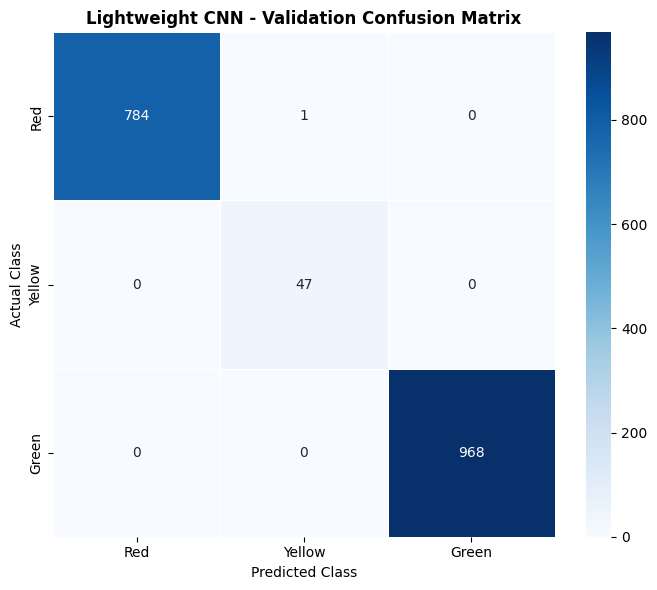


FINAL VALIDATION MODEL COMPARISON


,Model,Evaluation Split,Accuracy (%),Macro Precision,Macro Recall,Macro F1-score,Weighted F1-score,Validation Loss,Parameters
0,Basic CNN,Validation,100.000000,1.000000,1.000000,1.000000,1.000000,0.000524,1142339
1,CNN with Augmentation,Validation,100.000000,1.000000,1.000000,1.000000,1.000000,0.000284,1142339
2,CNN with Class Weight,Validation,100.000000,1.000000,1.000000,1.000000,1.000000,0.000072,1142339
3,CNN with Augmentation and Class Weight,Validation,100.000000,1.000000,1.000000,1.000000,1.000000,0.000064,1142339
4,Proposed Lightweight CNN,Validation,99.944444,0.993056,0.999575,0.996279,0.999447,0.002529,110147



EXP-05 Evaluation Completed!


In [45]:

# =============================================
# 42. LIGHTWEIGHT CNN VALIDATION EVALUATION
# =============================================

# Evaluate restored best model
lightweight_val_loss, lightweight_val_acc = (
    lightweight_cnn.evaluate(
        val_dataset,
        verbose=0
    )
)

# Generate validation predictions
y_val_prob_lightweight = lightweight_cnn.predict(
    val_dataset,
    verbose=0
)

y_val_pred_lightweight = np.argmax(
    y_val_prob_lightweight,
    axis=1
)

assert len(y_val_pred_lightweight) == len(y_val)

# Calculate metrics
lightweight_metrics = pd.DataFrame([{

    "Model": "Proposed Lightweight CNN",

    "Evaluation Split": "Validation",

    "Accuracy (%)": accuracy_score(
        y_val, y_val_pred_lightweight
    ) * 100,

    "Macro Precision": precision_score(
        y_val,
        y_val_pred_lightweight,
        average="macro",
        zero_division=0
    ),

    "Macro Recall": recall_score(
        y_val,
        y_val_pred_lightweight,
        average="macro",
        zero_division=0
    ),

    "Macro F1-score": f1_score(
        y_val,
        y_val_pred_lightweight,
        average="macro",
        zero_division=0
    ),

    "Weighted F1-score": f1_score(
        y_val,
        y_val_pred_lightweight,
        average="weighted",
        zero_division=0
    ),

    "Validation Loss": lightweight_val_loss

}])

print("=" * 60)
print("EXP-05 VALIDATION RESULTS")
print("=" * 60)

display(lightweight_metrics)

# Save evaluation metrics
lightweight_metrics.to_csv(
    OUTPUT_DIR /
    "lightweight_cnn_validation_metrics.csv",
    index=False
)

# Generate classification report
report_lightweight = classification_report(
    y_val,
    y_val_pred_lightweight,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_lightweight_df = pd.DataFrame(
    report_lightweight
).transpose()

print("\nCLASSIFICATION REPORT")

display(report_lightweight_df.round(4))

report_lightweight_df.to_csv(
    OUTPUT_DIR /
    "lightweight_cnn_classification_report.csv"
)

# Generate confusion matrix
cm_lightweight = confusion_matrix(
    y_val,
    y_val_pred_lightweight,
    labels=[0, 1, 2]
)

fig, ax = plt.subplots(figsize=(7, 6))

sns.heatmap(
    cm_lightweight,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    linewidths=0.5,
    ax=ax
)

ax.set_title(
    "Lightweight CNN - Validation Confusion Matrix",
    fontweight="bold"
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR /
    "lightweight_cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR /
    "lightweight_cnn_confusion_matrix.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Save confusion matrix values
pd.DataFrame(
    cm_lightweight,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    OUTPUT_DIR /
    "lightweight_cnn_confusion_matrix.csv"
)

# Compare all five experiments
comparison_df = pd.concat(
    [
        basic_metrics,
        augmented_metrics,
        weighted_metrics,
        combined_metrics,
        lightweight_metrics
    ],
    ignore_index=True
)

comparison_df["Parameters"] = [
    basic_cnn.count_params(),
    augmented_cnn.count_params(),
    weighted_cnn.count_params(),
    combined_cnn.count_params(),
    lightweight_cnn.count_params()
]

print("\nFINAL VALIDATION MODEL COMPARISON")

display(comparison_df.round(6))

comparison_df.to_csv(
    OUTPUT_DIR /
    "model_comparison_validation.csv",
    index=False
)

print("\nEXP-05 Evaluation Completed!")


## 9. Comprehensive Model Comparison

### 9.1 Computational Efficiency Analysis

The computational efficiency of the five CNN
configurations is evaluated in terms of model
parameters, storage requirements, training time,
inference latency, and throughput.

In [46]:

# =============================================
# 43. COMPUTATIONAL EFFICIENCY ANALYSIS
# =============================================

import time
import gc

# Experiment configurations
experiment_configs = [
    ("EXP-01", "Basic CNN", "basic_cnn"),
    ("EXP-02", "CNN + Augmentation", "augmented_cnn"),
    ("EXP-03", "CNN + Class Weight", "weighted_cnn"),
    ("EXP-04", "Combined CNN", "combined_cnn"),
    ("EXP-05", "Lightweight CNN", "lightweight_cnn")
]

# Benchmark configuration
BENCHMARK_BATCH = 64
WARMUP_RUNS = 10
BENCHMARK_RUNS = 50

assert tf.config.list_physical_devices("GPU")

# Use identical validation images for all models
with tf.device("/GPU:0"):

    benchmark_input = tf.convert_to_tensor(
        X_val[:BENCHMARK_BATCH],
        dtype=tf.float32
    )

efficiency_results = []

baseline_parameters = basic_cnn.count_params()

for exp_id, model_name, prefix in experiment_configs:

    print(f"\nBenchmarking {exp_id}: {model_name}")

    # Locate saved model
    model_path = MODEL_DIR / f"{prefix}_best.keras"

    # Load training summary
    summary_path = (
        OUTPUT_DIR /
        f"{prefix}_experiment_summary.csv"
    )

    summary = pd.read_csv(summary_path).iloc[0]

    # Saved checkpoint size in MiB
    model_size = model_path.stat().st_size / (1024 ** 2)

    # Load model on a single GPU
    with tf.device("/GPU:0"):

        benchmark_model = keras.models.load_model(
            str(model_path),
            compile=False
        )

        parameters = benchmark_model.count_params()

        @tf.function
        def inference(images):
            return benchmark_model(
                images,
                training=False
            )

        # Warm-up runs
        for _ in range(WARMUP_RUNS):
            inference(benchmark_input).numpy()

        # Measure inference latency
        inference_times = []

        for _ in range(BENCHMARK_RUNS):

            start = time.perf_counter()

            predictions = inference(
                benchmark_input
            ).numpy()

            elapsed = time.perf_counter() - start

            inference_times.append(elapsed)

    # Median batch inference latency
    median_batch_time = np.median(inference_times)

    batch_latency_ms = median_batch_time * 1000

    per_image_ms = (
        batch_latency_ms / BENCHMARK_BATCH
    )

    throughput = (
        BENCHMARK_BATCH / median_batch_time
    )

    reduction = (
        (baseline_parameters - parameters)
        / baseline_parameters * 100
    )

    efficiency_results.append({

        "Experiment": exp_id,

        "Model": model_name,

        "Parameters": parameters,

        "Checkpoint Size (MiB)": model_size,

        "Training Time (Seconds)":
            summary["Training Time (Seconds)"],

        "Completed Epochs":
            int(summary["Completed Epochs"]),

        "Best Epoch":
            int(summary["Best Epoch"]),

        "Batch Latency (ms)": batch_latency_ms,

        "Amortized Time per Image (ms)": per_image_ms,

        "Throughput (Images/sec)": throughput,

        "Parameter Reduction (%)": reduction

    })

    print(f"Parameters: {parameters:,}")
    print(f"Checkpoint Size: {model_size:.4f} MiB")
    print(f"Batch Latency: {batch_latency_ms:.4f} ms")
    print(f"Throughput: {throughput:.2f} images/sec")

    del inference
    del benchmark_model

    gc.collect()

# Create efficiency comparison table
efficiency_df = pd.DataFrame(efficiency_results)

print("\n" + "=" * 60)
print("COMPUTATIONAL EFFICIENCY COMPARISON")
print("=" * 60)

display(efficiency_df.round(4))

# Save research results
efficiency_df.to_csv(
    OUTPUT_DIR / "computational_efficiency.csv",
    index=False
)

print("\nComputational Efficiency Analysis Completed!")



Benchmarking EXP-01: Basic CNN
Parameters: 1,142,339
Checkpoint Size: 13.1183 MiB
Batch Latency: 2.8387 ms
Throughput: 22545.36 images/sec

Benchmarking EXP-02: CNN + Augmentation
Parameters: 1,142,339
Checkpoint Size: 13.1316 MiB
Batch Latency: 2.3518 ms
Throughput: 27213.30 images/sec

Benchmarking EXP-03: CNN + Class Weight
Parameters: 1,142,339
Checkpoint Size: 13.1183 MiB
Batch Latency: 2.3219 ms
Throughput: 27563.24 images/sec

Benchmarking EXP-04: Combined CNN
Parameters: 1,142,339
Checkpoint Size: 13.1316 MiB
Batch Latency: 2.3258 ms
Throughput: 27516.86 images/sec

Benchmarking EXP-05: Lightweight CNN
Parameters: 110,147
Checkpoint Size: 1.3159 MiB
Batch Latency: 2.2369 ms
Throughput: 28611.64 images/sec

COMPUTATIONAL EFFICIENCY COMPARISON


,Experiment,Model,Parameters,Checkpoint Size (MiB),Training Time (Seconds),Completed Epochs,Best Epoch,Batch Latency (ms),Amortized Time per Image (ms),Throughput (Images/sec),Parameter Reduction (%)
0,EXP-01,Basic CNN,1142339,13.1183,31.9510,7,2,2.8387,0.0444,22545.3646,0.0000
1,EXP-02,CNN + Augmentation,1142339,13.1316,35.7510,9,4,2.3518,0.0367,27213.3025,0.0000
2,EXP-03,CNN + Class Weight,1142339,13.1183,59.5860,16,11,2.3219,0.0363,27563.2356,0.0000
3,EXP-04,Combined CNN,1142339,13.1316,76.6769,20,15,2.3258,0.0363,27516.8632,0.0000
4,EXP-05,Lightweight CNN,110147,1.3159,63.6488,17,12,2.2369,0.0350,28611.6381,90.3578



Computational Efficiency Analysis Completed!


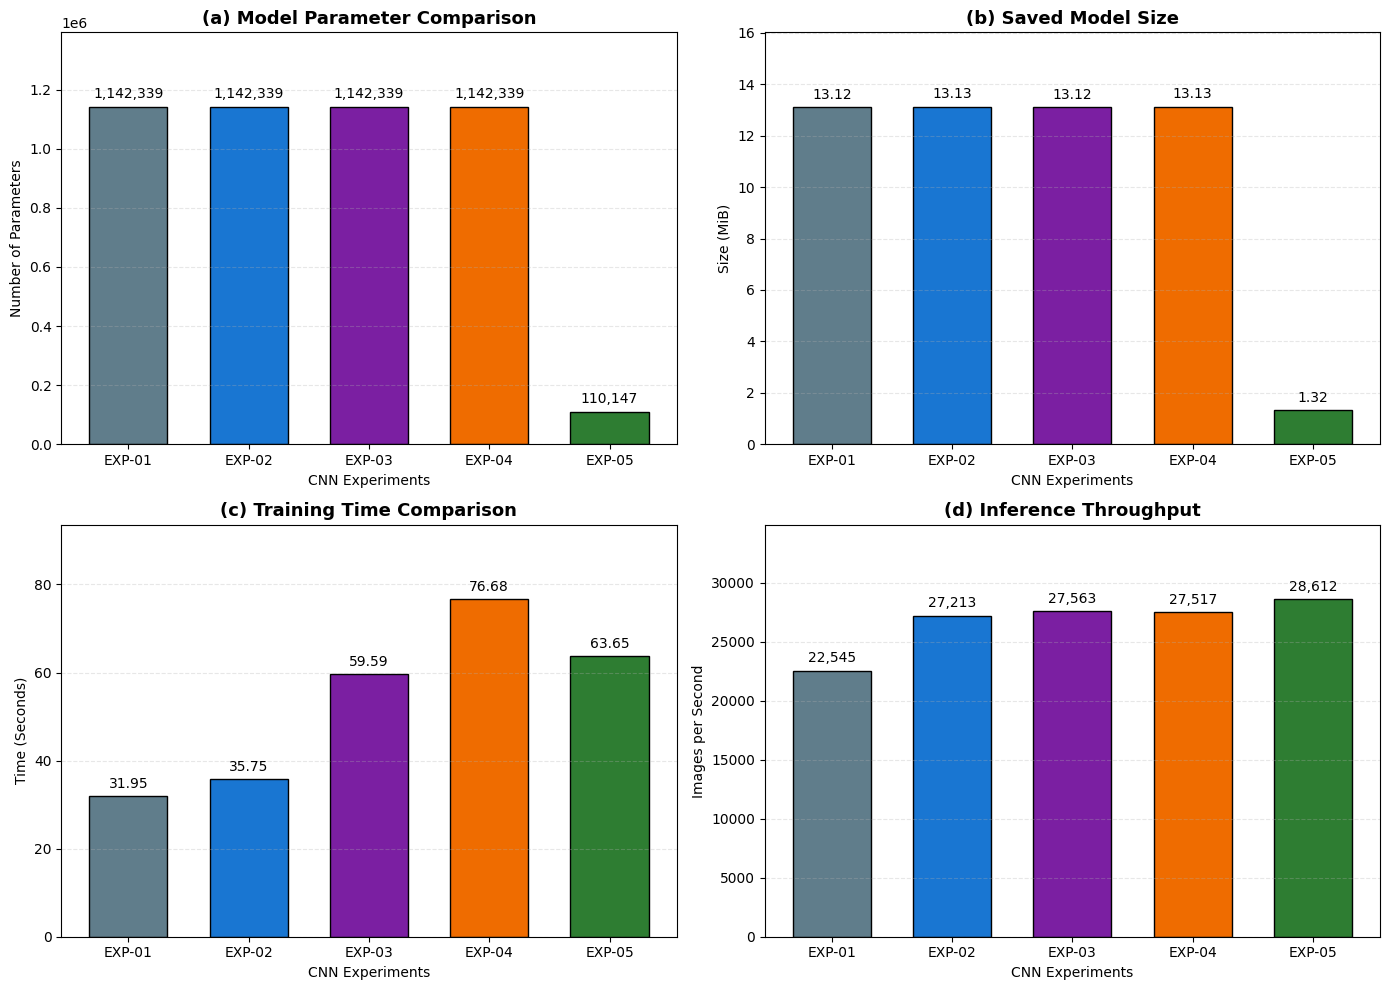

Computational Efficiency Graphs Saved!


In [47]:

# =============================================
# 44. COMPUTATIONAL EFFICIENCY VISUALIZATION
# =============================================

experiment_labels = efficiency_df["Experiment"]

colors = [
    "#607D8B",
    "#1976D2",
    "#7B1FA2",
    "#EF6C00",
    "#2E7D32"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

plot_configs = [

    (
        "Parameters",
        "(a) Model Parameter Comparison",
        "Number of Parameters",
        "{:,.0f}"
    ),

    (
        "Checkpoint Size (MiB)",
        "(b) Saved Model Size",
        "Size (MiB)",
        "{:.2f}"
    ),

    (
        "Training Time (Seconds)",
        "(c) Training Time Comparison",
        "Time (Seconds)",
        "{:.2f}"
    ),

    (
        "Throughput (Images/sec)",
        "(d) Inference Throughput",
        "Images per Second",
        "{:,.0f}"
    )

]

for ax, config in zip(axes.flat, plot_configs):

    column, title, ylabel, label_format = config

    values = efficiency_df[column].to_numpy()

    bars = ax.bar(
        experiment_labels,
        values,
        color=colors,
        edgecolor="black",
        width=0.65
    )

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("CNN Experiments")
    ax.set_ylabel(ylabel)

    ax.set_ylim(0, values.max() * 1.22)

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

    for bar, value in zip(bars, values):

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + values.max() * 0.025,
            label_format.format(value),
            ha="center",
            fontsize=10
        )

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "computational_efficiency.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "computational_efficiency.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Computational Efficiency Graphs Saved!")


## 10. Group-Based Cross-Validation

### 10.1 Five-Fold Stratified Group Cross-Validation

Five-fold group-based cross-validation is performed
on the development dataset to evaluate the stability
of the proposed Lightweight CNN.

Video sequences are treated as groups to minimize
the risk of data leakage between folds.

An inner validation subset is used for early stopping,
while the outer held-out fold is used for evaluation.

The independent test dataset remains excluded.

In [48]:

# =============================================
# 45. CROSS-VALIDATION DATASET PREPARATION
# =============================================

from sklearn.model_selection import (
    StratifiedGroupKFold,
    GroupShuffleSplit
)

# Exclude independent test dataset
dev_mask = preprocess_df["Split"].isin(
    ["Train", "Validation"]
).to_numpy()

X_dev = X_normalized[dev_mask]
y_dev = y[dev_mask]

groups_dev = preprocess_df.loc[
    dev_mask, "Sequence"
].to_numpy()

assert len(X_dev) == len(y_dev) == len(groups_dev)
assert len(X_dev) == 10200

test_groups = set(
    preprocess_df.loc[
        preprocess_df["Split"] == "Test",
        "Sequence"
    ]
)

assert set(groups_dev).isdisjoint(test_groups)

N_SPLITS = 5

print("Cross-Validation Samples:", len(X_dev))
print("Unique Video Sequences:", len(set(groups_dev)))
print("Independent Test Samples Excluded:", len(X_test))

print("\nClass Distribution by Sequence:")

display(pd.crosstab(
    groups_dev,
    y_dev
).rename(columns={
    0: "Red",
    1: "Yellow",
    2: "Green"
}))

# Check whether all classes are present
def has_all_classes(indices):
    return len(np.unique(y_dev[indices])) == 3

# Find a feasible grouped cross-validation plan
cv_plan = None

for seed in range(SEED, SEED + 50):

    sgkf = StratifiedGroupKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=seed
    )

    candidate_plan = []

    for outer_train, outer_eval in sgkf.split(
        X_dev, y_dev, groups_dev
    ):

        if not has_all_classes(outer_eval):
            break

        # Inner validation for early stopping
        inner_splitter = GroupShuffleSplit(
            n_splits=100,
            test_size=0.20,
            random_state=seed
        )

        inner_found = False

        for fit_rel, val_rel in inner_splitter.split(
            outer_train,
            groups=groups_dev[outer_train]
        ):

            fit_idx = outer_train[fit_rel]
            val_idx = outer_train[val_rel]

            if (
                has_all_classes(fit_idx)
                and has_all_classes(val_idx)
            ):

                candidate_plan.append(
                    (fit_idx, val_idx, outer_eval)
                )

                inner_found = True
                break

        if not inner_found:
            break

    if len(candidate_plan) == N_SPLITS:

        cv_plan = candidate_plan
        cv_seed = seed
        break

if cv_plan is None:
    raise ValueError(
        "No feasible 5-fold split containing "
        "all three classes was found."
    )

# Audit cross-validation splits
fold_details = []

for fold, (fit_idx, val_idx, eval_idx) in enumerate(
    cv_plan, start=1
):

    fit_groups = set(groups_dev[fit_idx])
    val_groups = set(groups_dev[val_idx])
    eval_groups = set(groups_dev[eval_idx])

    assert fit_groups.isdisjoint(val_groups)
    assert fit_groups.isdisjoint(eval_groups)
    assert val_groups.isdisjoint(eval_groups)

    fold_details.append({
        "Fold": fold,
        "Training Samples": len(fit_idx),
        "Inner Validation Samples": len(val_idx),
        "Evaluation Samples": len(eval_idx),
        "Evaluation Red": int(
            np.sum(y_dev[eval_idx] == 0)
        ),
        "Evaluation Yellow": int(
            np.sum(y_dev[eval_idx] == 1)
        ),
        "Evaluation Green": int(
            np.sum(y_dev[eval_idx] == 2)
        )
    })

cv_split_table = pd.DataFrame(fold_details)

print("\nCROSS-VALIDATION SPLIT DETAILS")
display(cv_split_table)

cv_split_table.to_csv(
    OUTPUT_DIR / "cross_validation_splits.csv",
    index=False
)

print("\nSelected Split Seed:", cv_seed)
print("Sequence Overlap: None")
print("Cross-Validation Dataset Ready!")


Cross-Validation Samples: 10200
Unique Video Sequences: 18
Independent Test Samples Excluded: 1800

Class Distribution by Sequence:


col_0,Red,Yellow,Green
row_0,,,
dayClip1,465,0,424
dayClip10,0,0,33
dayClip11,314,0,87
dayClip12,0,0,57
dayClip13,223,146,121
dayClip2,289,0,184
dayClip3,111,10,13
dayClip4,0,0,197
dayClip5,1019,291,968



CROSS-VALIDATION SPLIT DETAILS


,Fold,Training Samples,Inner Validation Samples,Evaluation Samples,Evaluation Red,Evaluation Yellow,Evaluation Green
0,1,4911,3011,2278,1019,291,968
1,2,4789,4437,974,499,157,318
2,3,5568,2404,2228,627,28,1573
3,4,6710,755,2735,1199,267,1269
4,5,6985,1230,1985,1220,146,619



Selected Split Seed: 45
Sequence Overlap: None
Cross-Validation Dataset Ready!


In [49]:

# =============================================
# 46. FIVE-FOLD CROSS-VALIDATION TRAINING
# =============================================

from sklearn.utils.class_weight import compute_class_weight

cv_results = []
cv_histories = {}

print("=" * 60)
print("LIGHTWEIGHT CNN CROSS-VALIDATION")
print("=" * 60)

for fold, (fit_idx, val_idx, eval_idx) in enumerate(
    cv_plan, start=1
):

    print(f"\n{'=' * 50}")
    print(f"FOLD {fold}/{N_SPLITS}")
    print(f"{'=' * 50}")

    keras.utils.set_random_seed(SEED + fold)

    # Calculate class weights from this fold only
    fold_weights_array = compute_class_weight(
        class_weight="balanced",
        classes=np.array([0, 1, 2]),
        y=y_dev[fit_idx]
    )

    fold_weights = {
        i: float(w)
        for i, w in enumerate(fold_weights_array)
    }

    # Prepare fold-specific datasets
    with tf.device("/CPU:0"):

        fold_train_ds = (
            tf.data.Dataset
            .from_tensor_slices(
                (X_dev[fit_idx], y_dev[fit_idx])
            )
            .shuffle(
                len(fit_idx),
                seed=SEED + fold
            )
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE)
        )

        fold_val_ds = (
            tf.data.Dataset
            .from_tensor_slices(
                (X_dev[val_idx], y_dev[val_idx])
            )
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE)
        )

        fold_eval_ds = (
            tf.data.Dataset
            .from_tensor_slices(
                (X_dev[eval_idx], y_dev[eval_idx])
            )
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE)
        )

    # Create fresh model on both GPUs
    with strategy.scope():

        fold_model = keras.models.clone_model(
            lightweight_cnn
        )

        fold_model.compile(

            optimizer=keras.optimizers.Adam(
                learning_rate=0.001
            ),

            loss="sparse_categorical_crossentropy",

            metrics=["accuracy"]
        )

    # Fresh callbacks for every fold
    fold_callbacks = [

        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            mode="min"
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6
        )
    ]

    start_time = time.perf_counter()

    # Train without accessing the outer fold
    fold_history = fold_model.fit(

        fold_train_ds,

        validation_data=fold_val_ds,

        epochs=EPOCHS,

        class_weight=fold_weights,

        callbacks=fold_callbacks,

        verbose=0
    )

    fold_training_time = (
        time.perf_counter() - start_time
    )

    # Evaluate the held-out fold
    fold_loss, _ = fold_model.evaluate(
        fold_eval_ds,
        verbose=0
    )

    fold_probabilities = fold_model.predict(
        fold_eval_ds,
        verbose=0
    )

    fold_predictions = np.argmax(
        fold_probabilities,
        axis=1
    )

    fold_true = y_dev[eval_idx]

    # Calculate metrics
    fold_accuracy = accuracy_score(
        fold_true, fold_predictions
    )

    fold_precision = precision_score(
        fold_true,
        fold_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    fold_recall = recall_score(
        fold_true,
        fold_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    fold_f1 = f1_score(
        fold_true,
        fold_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    yellow_recall = recall_score(
        fold_true,
        fold_predictions,
        labels=[1],
        average=None,
        zero_division=0
    )[0]

    # Save training history
    fold_history_df = pd.DataFrame(
        fold_history.history
    )

    cv_histories[fold] = fold_history_df

    fold_history_df.to_csv(
        OUTPUT_DIR / f"cv_fold_{fold}_history.csv",
        index=False
    )

    # Record fold results
    cv_results.append({

        "Fold": fold,

        "Accuracy (%)": fold_accuracy * 100,

        "Macro Precision": fold_precision,

        "Macro Recall": fold_recall,

        "Macro F1-score": fold_f1,

        "Yellow Recall": yellow_recall,

        "Evaluation Loss": fold_loss,

        "Evaluation Samples": len(eval_idx),

        "Completed Epochs": len(fold_history_df),

        "Best Epoch": int(
            fold_history_df["val_loss"].argmin() + 1
        ),

        "Training Time (Seconds)": fold_training_time
    })

    print(f"Accuracy: {fold_accuracy * 100:.4f}%")
    print(f"Macro Precision: {fold_precision:.4f}")
    print(f"Macro Recall: {fold_recall:.4f}")
    print(f"Macro F1-score: {fold_f1:.4f}")
    print(f"Yellow Recall: {yellow_recall:.4f}")
    print(f"Training Time: {fold_training_time:.2f} sec")

    del fold_model
    del fold_history

    gc.collect()

# Combine all fold results
cv_results_df = pd.DataFrame(cv_results)

print("\n" + "=" * 60)
print("FIVE-FOLD CROSS-VALIDATION RESULTS")
print("=" * 60)

display(cv_results_df.round(6))

# Save results
cv_results_df.to_csv(
    OUTPUT_DIR / "cross_validation_results.csv",
    index=False
)

print("\nCross-Validation Training Completed!")


LIGHTWEIGHT CNN CROSS-VALIDATION

FOLD 1/5
INFO:tensorflow:Collective all_reduce tensors: 10 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
Accuracy: 100.0000%
Macro Precision: 1.0000
Macro Recall: 1.0000
Macro F1-score: 1.0000
Yellow Recall: 1.0000
Training Time: 72.70 sec

FOLD 2/5
INFO:tensorflow:Collective all_reduce tensors: 10 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
Accuracy: 99.1786%
Macro Precision: 0.9876
Macro Recall: 0.9914
Macro F1-score: 0.9894
Yellow Recall: 0.9873
Training Time: 43.30 sec

FOLD 3/5
INFO:tensorflow:Collective all_reduce tensors: 10 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
Accuracy: 99.9102%
Macro Precision: 0.9778
Macro Recall: 0.9993
Macro F1-score: 0.9881
Yellow Recall: 1.0000
Training Time: 31.20 sec

FOLD 4/5
INFO:tensorflow:Collective all_reduce ten

,Fold,Accuracy (%),Macro Precision,Macro Recall,Macro F1-score,Yellow Recall,Evaluation Loss,Evaluation Samples,Completed Epochs,Best Epoch,Training Time (Seconds)
0,1,100.000000,1.000000,1.000000,1.000000,1.000000,0.003361,2278,25,20,72.697040
1,2,99.178645,0.987571,0.991365,0.989437,0.987261,0.063116,974,13,8,43.298257
2,3,99.910233,0.977778,0.999256,0.988134,1.000000,0.007988,2228,10,5,31.204284
3,4,94.917733,0.965371,0.826467,0.864437,0.479401,0.112067,2735,11,6,33.646585
4,5,90.831234,0.850202,0.668890,0.652046,0.041096,0.770081,1985,16,11,50.464255



Cross-Validation Training Completed!


In [51]:

# =============================================
# 47. CROSS-VALIDATION STATISTICAL ANALYSIS
# =============================================

metric_columns = [
    "Accuracy (%)",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-score",
    "Yellow Recall",
    "Evaluation Loss"
]

cv_statistics = pd.DataFrame({

    "Mean": cv_results_df[
        metric_columns
    ].mean(),

    "Standard Deviation": cv_results_df[
        metric_columns
    ].std(ddof=1),

    "Minimum": cv_results_df[
        metric_columns
    ].min(),

    "Maximum": cv_results_df[
        metric_columns
    ].max()
})

print("=" * 60)
print("CROSS-VALIDATION STATISTICAL SUMMARY")
print("=" * 60)

display(cv_statistics.round(6))

print("\nMean Accuracy ± Standard Deviation:")

print(
    f"{cv_statistics.loc['Accuracy (%)', 'Mean']:.4f}% "
    f"± "
    f"{cv_statistics.loc['Accuracy (%)', 'Standard Deviation']:.4f}"
    f" percentage points"
)

print("\nMean Macro F1-score:")

print(
    f"{cv_statistics.loc['Macro F1-score', 'Mean']:.6f}"
)

cv_statistics.to_csv(
    OUTPUT_DIR / "cross_validation_statistics.csv"
)

print("\nStatistical Analysis Saved Successfully!")


CROSS-VALIDATION STATISTICAL SUMMARY


,Mean,Standard Deviation,Minimum,Maximum
Accuracy (%),96.967569,4.018712,90.831234,100.000000
Macro Precision,0.956185,0.060597,0.850202,1.000000
Macro Recall,0.897196,0.147461,0.668890,1.000000
Macro F1-score,0.898811,0.148749,0.652046,1.000000
Yellow Recall,0.701552,0.431661,0.041096,1.000000
Evaluation Loss,0.191323,0.326581,0.003361,0.770081



Mean Accuracy ± Standard Deviation:
96.9676% ± 4.0187 percentage points

Mean Macro F1-score:
0.898811

Statistical Analysis Saved Successfully!


In [52]:

# =============================================
# 45. COMPLETE RESEARCH BACKUP
# =============================================

import zipfile
import json
import sys
import os

from pathlib import Path
from IPython.display import FileLink, display

# Working directory
WORK_DIR = Path("/kaggle/working")

BACKUP_DIR = WORK_DIR / "research_backup"

BACKUP_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Important research folders
backup_folders = [
    "preprocessed_dataset",
    "saved_models",
    "research_outputs"
]

# Verify required dataset and model files
required_files = {
    "preprocessed_dataset": [
        "X_train.npy",
        "y_train.npy",
        "X_val.npy",
        "y_val.npy",
        "X_test.npy",
        "y_test.npy",
        "dataset_metadata.csv"
    ],
    "saved_models": [
        "basic_cnn_best.keras",
        "augmented_cnn_best.keras",
        "weighted_cnn_best.keras",
        "combined_cnn_best.keras",
        "lightweight_cnn_best.keras"
    ],
    "research_outputs": [
        "model_comparison_validation.csv",
        "computational_efficiency.csv",
        "validated_annotations.csv"
    ]
}

for folder_name, filenames in required_files.items():

    for filename in filenames:

        path = WORK_DIR / folder_name / filename

        if not path.is_file():
            raise FileNotFoundError(path)

# Save experiment environment information
environment = {
    "Python": sys.version,
    "TensorFlow": tf.__version__,
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "OpenCV": cv2.__version__,
    "Dataset": "LISA Traffic Light Dataset",
    "Dataset URL":
        "https://www.kaggle.com/datasets/mbornoe/lisa-traffic-light-dataset",
    "Random Seed": 42,
    "Image Size": [64, 64, 3],
    "Total Images": 12000,
    "Training Images": 8400,
    "Validation Images": 1800,
    "Testing Images": 1800,
    "Class Mapping": {
        "Red": 0,
        "Yellow": 1,
        "Green": 2
    }
}

with open(
    WORK_DIR / "research_outputs" /
    "experiment_environment.json",
    "w"
) as file:

    json.dump(environment, file, indent=4)

print("=" * 60)
print("CREATING RESEARCH BACKUP")
print("=" * 60)

total_backup_size = 0

# Create separate ZIP backups
for folder_name in backup_folders:

    source_folder = WORK_DIR / folder_name

    zip_path = BACKUP_DIR / f"{folder_name}.zip"

    files = sorted([
        file for file in source_folder.rglob("*")
        if file.is_file()
    ])

    if not files:
        raise ValueError(f"Empty folder: {source_folder}")

    print(f"\nBacking up: {folder_name}")

    with zipfile.ZipFile(
        zip_path,
        mode="w",
        compression=zipfile.ZIP_DEFLATED
    ) as archive:

        for file in files:

            archive.write(
                file,
                arcname=file.relative_to(WORK_DIR)
            )

    # Verify ZIP file integrity
    with zipfile.ZipFile(zip_path, "r") as archive:

        corrupted_file = archive.testzip()

        if corrupted_file is not None:

            raise RuntimeError(
                f"Corrupted file: {corrupted_file}"
            )

    size_mb = zip_path.stat().st_size / (1024 ** 2)

    total_backup_size += size_mb

    print("Files Included:", len(files))
    print(f"Backup Size: {size_mb:.2f} MiB")
    print("Integrity Check: PASSED")
    print("Backup Created:", zip_path.name)

print("\n" + "=" * 60)
print("BACKUP COMPLETED SUCCESSFULLY")
print("=" * 60)

print(f"Total Backup Size: {total_backup_size:.2f} MiB")

print("\nDOWNLOAD YOUR BACKUP FILES:\n")

# Display download links
for file in sorted(BACKUP_DIR.glob("*.zip")):

    display(FileLink(str(file)))


CREATING RESEARCH BACKUP

Backing up: preprocessed_dataset
Files Included: 7
Backup Size: 56.61 MiB
Integrity Check: PASSED
Backup Created: preprocessed_dataset.zip

Backing up: saved_models
Files Included: 5
Backup Size: 50.18 MiB
Integrity Check: PASSED
Backup Created: saved_models.zip

Backing up: research_outputs
Files Included: 76
Backup Size: 5.90 MiB
Integrity Check: PASSED
Backup Created: research_outputs.zip

BACKUP COMPLETED SUCCESSFULLY
Total Backup Size: 112.69 MiB

DOWNLOAD YOUR BACKUP FILES:



/kaggle/working/research_backup/preprocessed_dataset.zip

/kaggle/working/research_backup/research_outputs.zip

/kaggle/working/research_backup/saved_models.zip

In [53]:
import os
from pathlib import Path
from IPython.display import FileLink, display

os.chdir("/kaggle/working")

backup_folder = Path("research_backup")

for file in sorted(backup_folder.glob("*.zip")):

    print(f"\nFile: {file.name}")
    print(f"Size: {file.stat().st_size / 1024**2:.2f} MiB")

    display(FileLink(str(file)))


File: preprocessed_dataset.zip
Size: 56.61 MiB


/kaggle/working/research_backup/preprocessed_dataset.zip


File: research_outputs.zip
Size: 5.90 MiB


/kaggle/working/research_backup/research_outputs.zip


File: saved_models.zip
Size: 50.18 MiB


/kaggle/working/research_backup/saved_models.zip